### Binary Saturation

This notebooks purpose is to simply do a sanity check on the analytical expressions found to describe the number of photons *lost* on an APD because of **binary saturation**. Quandelas software provides a plataform to simulate and use photonic quantum computers, implementing linear optics tools. The basics of *perceval*, their programming kit and a general description on how their computer works is described on another notebook *Perceval-Learning*. I will not delve deeper into this, in order to mantain the purpose of this notebook. However the gist of it is that they have quantum dot based single photon emmitters and can implement any unitary using a combination of beam-splitters and phase shifters. They also have Photon Number Resolving (PNR) detectors, which can also be set to work as an APD, by simply setting the threhsold of photons counted to 1. We can choose detector efficiencis and set many noise models to their circuits, which simulate our own setup. 

--- 

**Problem Statement:** Suppose you have a photon detector of the Geiger-type (binary response click or no-click), such as an Avalanche Photon Diode (APD) detector, and a Photon Number Resolving (PNR) detector. While your source can send single photons and photons that come in pairs. Since APDs cannot count two photons, everytime a pair arrives we will count only one, underestimating the true number of photons - a problem we will call **binary saturation**. How can we make sure that even with an APD we can still recover the total number of photon arrivals? 

--- 

This is a reasonable simplification of our real problem in Idor (which will be discussed further throught the notebook), however it does serve as an exercise in better understanding the problem we are dealing with and as a simple check on wheter or not the analytical expressions found work well even for this simple simulations. 

The answer to our problem is: yes, there is a way to recover the lost photons due to binary saturation and we have a definite expression for it, which will be given later.


In [2]:
# Perceval 1.3.0 is needed!!
import importlib.util, subprocess, sys

from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import perceval as pcvl
from perceval.simulators import Simulator
from perceval.backends import SLOSBackend

plt.rcParams.update({"figure.figsize": (6, 4), "font.size": 12,
                     "axes.grid": True, "grid.alpha": 0.3})
print("perceval", pcvl.__version__)

# Crisp plots on projectors and HiDPI screens (works on Colab too).
%config InlineBackend.figure_format = "retina"

perceval 1.3.0



One first experiment is simply to understand the average number of photons lost on APDs when comparing with PNR detectors:
$$
\Delta N = \langle N^{PNR}_{det}\rangle - \langle N^{APD}_{det}\rangle = \eta^2
$$

Where $\eta$ is the detector efficiency and we assume that $\eta^{PNR} = \eta^{APD}$. In this case we should be able to test it fairly simple, since we will have detectors of the same efficiency and we must simply impose on our PNR detector to work as an APD.

**Experiment:** One fiber connected to a PNR or to an APD. The light state which enters the fiber is $|2\rangle$ and we can tune the detector efficiencys to be $\eta \in [0,1]$. We expect to find the correct probabilities for detecting $P(0)$, $P(1)$ and (only for PNR) $P(2)$. From this we can calculate $\langle N \rangle = \sum_n n*P(n)$.


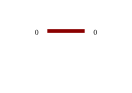

In [2]:
circuit = pcvl.Circuit(1)
pcvl.pdisplay(circuit)
# Circuit

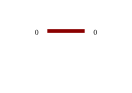

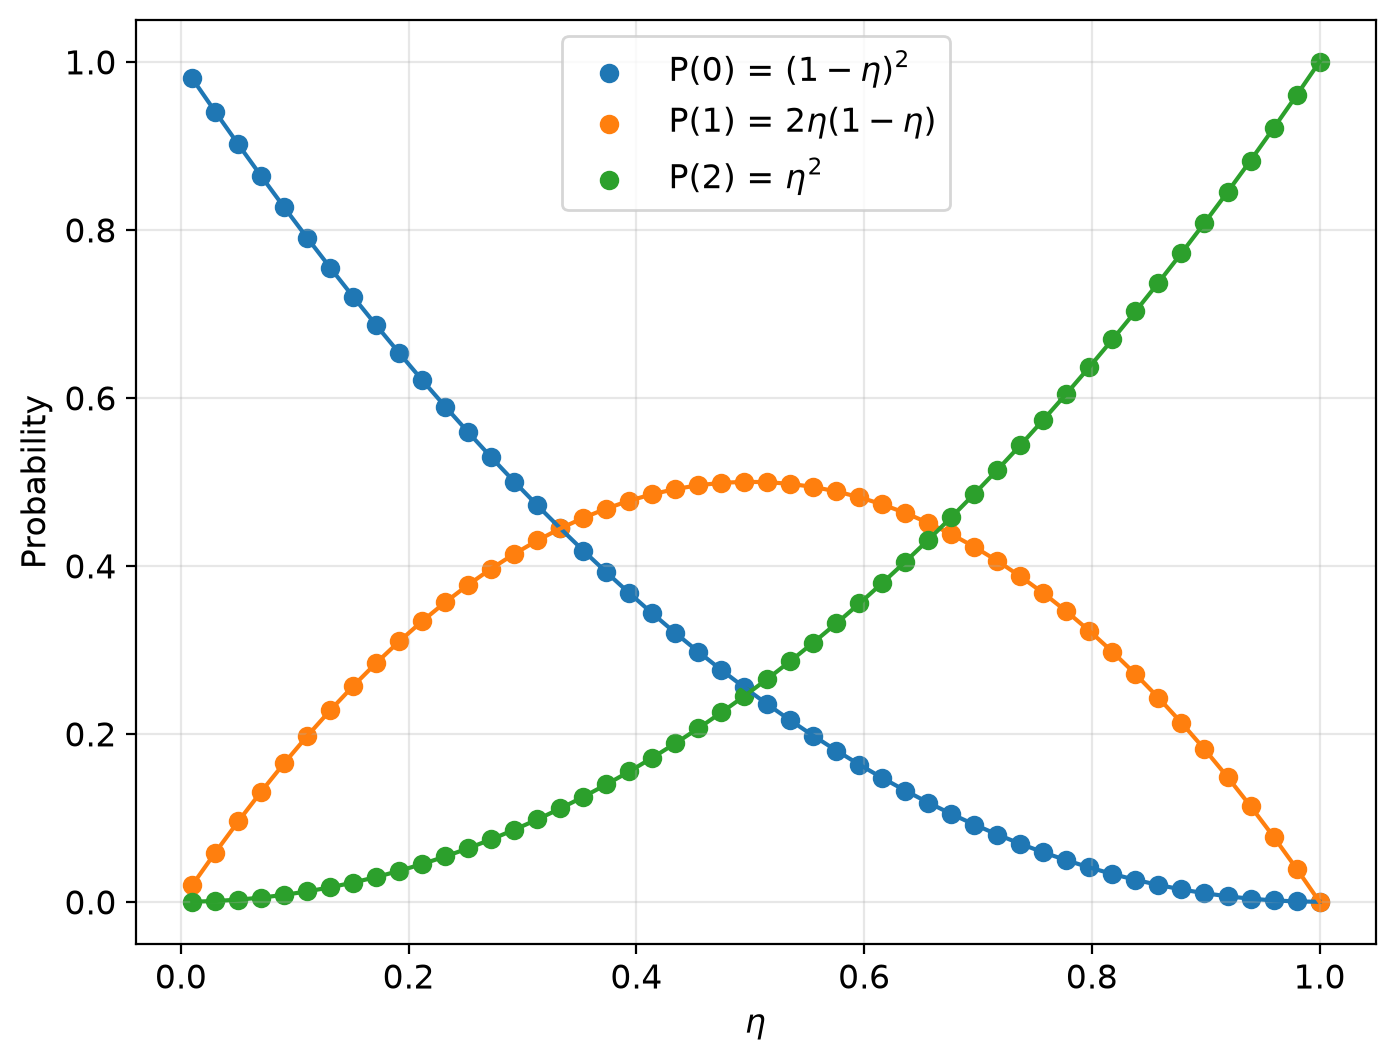

In [4]:

def simple():
    return pcvl.Circuit(1)

etas = np.linspace(0.01, 1, 50)


state = pcvl.BasicState('|2>')

result=[]
p0=[]
p1=[]
p2=[]

for eta in etas:
    proc = pcvl.Processor("SLOS", simple())
    detector = pcvl.Detector.pnr() # PNR
    detector.efficiency = eta # efficiency

    proc.add(0, detector)

    proc.with_input(state)
    proc.min_detected_photons_filter(0) ### detects at least 0 photons
    res = pcvl.algorithm.Sampler(proc).probs()['results']
    result.append(res)
    p0.append(res.get(pcvl.BasicState([0]), 0.0))
    p1.append(res.get(pcvl.BasicState([1]), 0.0))
    p2.append(res.get(pcvl.BasicState([2]), 0.0))

### Expected results:

p0_ = lambda x: (1-x)**2
p1_ = lambda x: 2*x*(1-x)
p2_ = lambda x: x**2


po_points = [p0_(eta) for eta in etas]
p1_points = [p1_(eta) for eta in etas]
p2_points = [p2_(eta) for eta in etas]


circuit = simple()
display(pcvl.pdisplay(circuit))

fig, (ax1) = plt.subplots(1,1, figsize=(8, 6))

ax1.scatter(etas, p0, label = r'P(0) = $(1-\eta)^2$')
ax1.scatter(etas, p1, label = r'P(1) = $2\eta(1 - \eta)$')
ax1.scatter(etas, p2, label = r'P(2) = $\eta^2$')

ax1.plot(etas, po_points)
ax1.plot(etas, p1_points)
ax1.plot(etas, p2_points)

ax1.set_xlabel(r'$\eta$')
ax1.set_ylabel(r'Probability')


plt.legend()
plt.show()

It works just as expected for the PNDs. 

By setting a threshold to our detector we obtain an APD (or any Geiger-type detector). 

In [6]:
from perceval.components import Detector
det = Detector.threshold()  #example!
N = 100
det.detect(N) #sent N photons but the detected state was 1

|1>

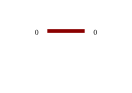

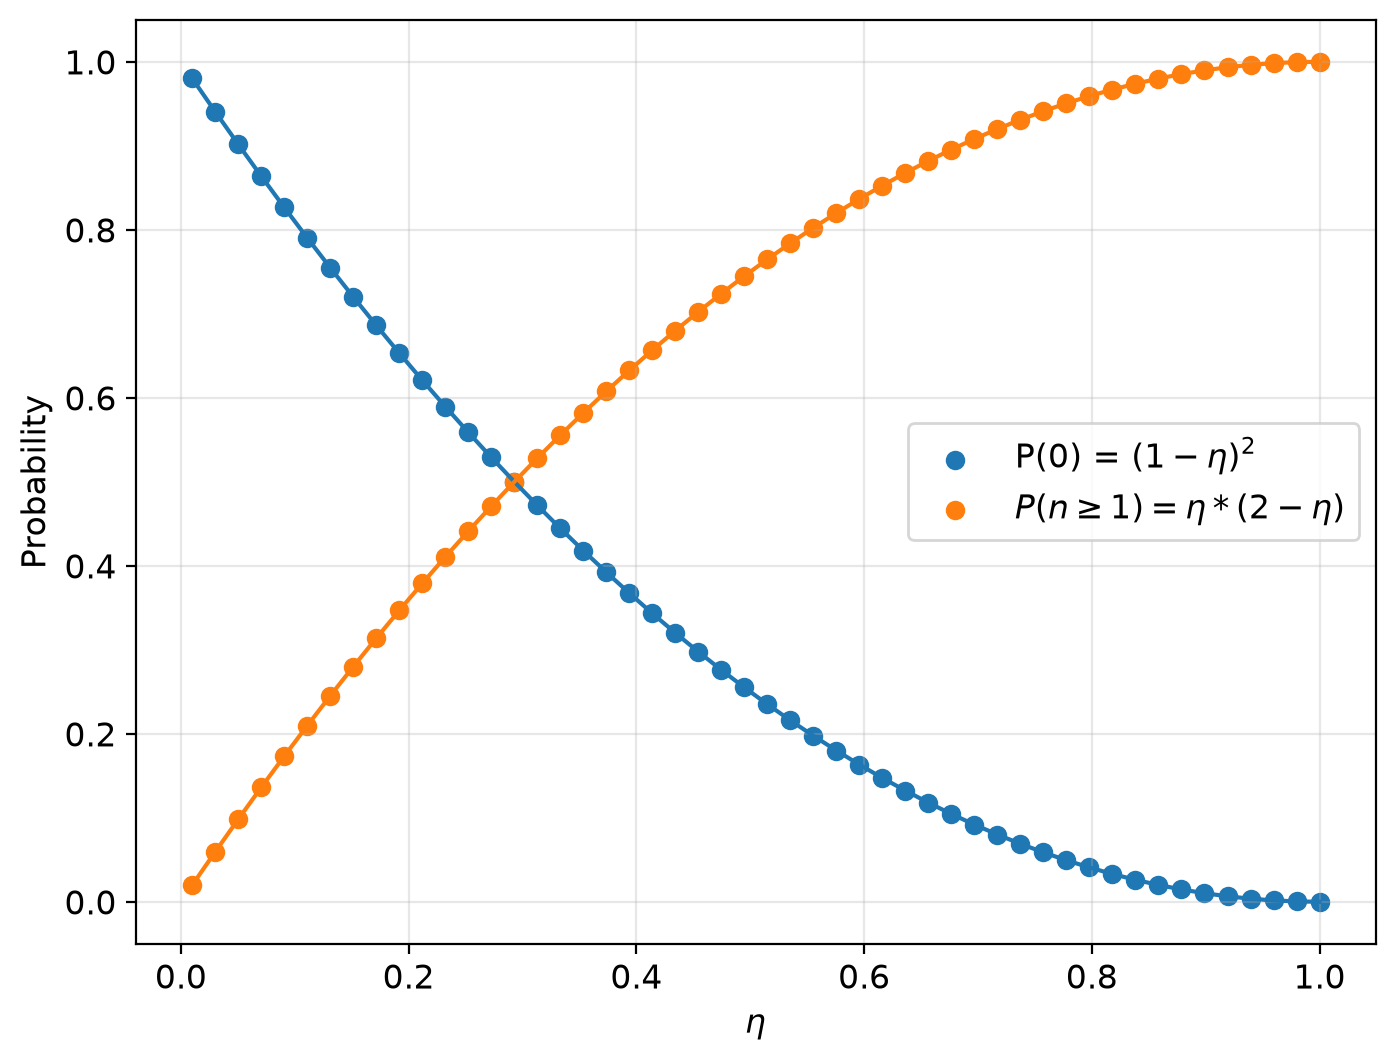

In [10]:

def simple():
    return pcvl.Circuit(1)

etas = np.linspace(0.01, 1, 50)


state = pcvl.BasicState('|2>') 

result=[]
p0_APD=[]
p1_APD=[]


for eta in etas:
    proc = pcvl.Processor("SLOS", simple())


    proc.with_input(state)

    detector = pcvl.Detector.threshold() # PNR
    detector.efficiency = eta # efficiency
    proc.add(0, detector)

    proc.min_detected_photons_filter(0) ### detecta com no minimo 1 fóton
    res = pcvl.algorithm.Sampler(proc).probs()['results']
    result.append(res)
    p0_APD.append(res.get(pcvl.BasicState([0]), 0.0))
    p1_APD.append(res.get(pcvl.BasicState([1]), 0.0))
   

### Expected results:

p0_ = lambda x: (1-x)**2
pgeq1 = lambda x: x*(2-x)

po_points = [p0_(eta) for eta in etas]
pgeq1_points = [pgeq1(eta) for eta in etas]



circuit = simple()
display(pcvl.pdisplay(circuit))

fig, (ax1) = plt.subplots(1,1, figsize=(8, 6))

ax1.scatter(etas, p0_APD, label = r'P(0) = $(1-\eta)^2$')
ax1.scatter(etas, p1_APD, label = r'$P(n \geq 1) = \eta*(2 - \eta)$')

plt.plot(etas, po_points)
plt.plot(etas, pgeq1_points)


ax1.set_xlabel(r'$\eta$')
ax1.set_ylabel(r'Probability')


plt.legend()
plt.show()

Now that we have both probability distributions we can calulate $\langle \Delta N \rangle$.

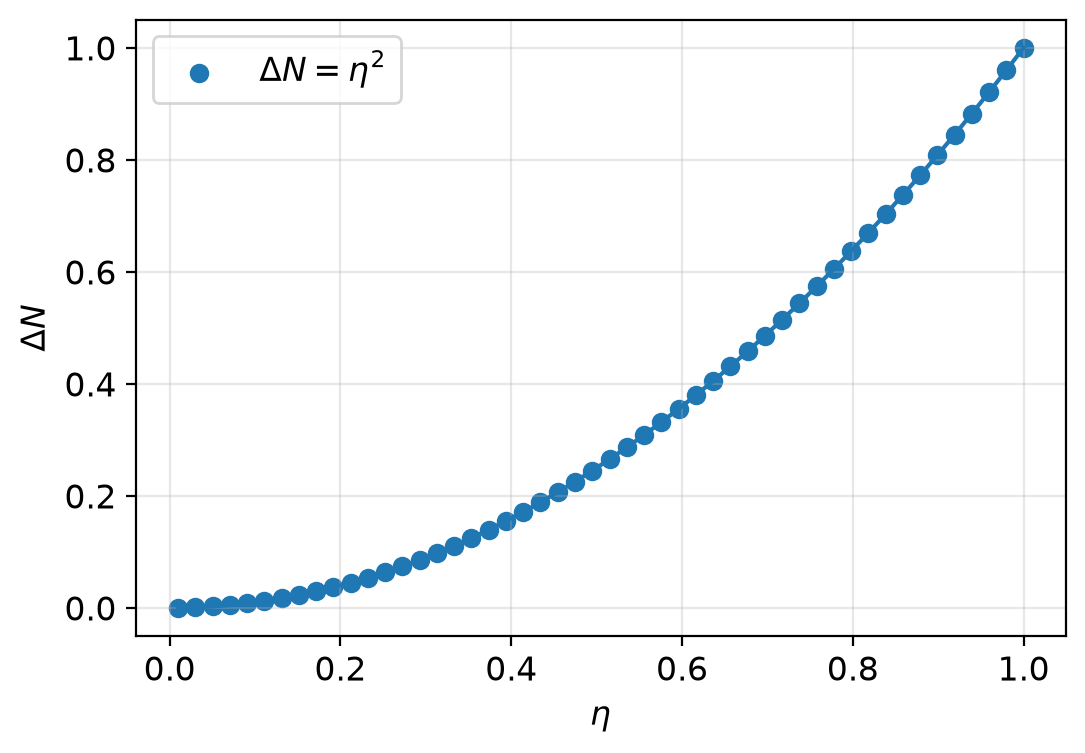

In [11]:
average_apd = np.array([ p0_APD[i]*0 + p1_APD[i]*1 for i in range(len(p0_APD))])
average_pnr = np.array([ p0[i]*0 + p1[i]*1 + p2[i]*2 for i in range(len(p0))])


avg_exp = lambda x : x**2

delta_N = average_pnr - average_apd


plt.scatter(etas, delta_N, label = r'$\Delta N = \eta^2$')
plt.plot(etas, [avg_exp(eta) for eta in etas])


plt.xlabel(r'$\eta$')
plt.ylabel(r'$\Delta N$')
plt.legend()
plt.show()

As seen above there is a clear relation between the number of photons which we measure with an APD when compared to a PNR. We still haven't found, however, a way to correct this discrepancy. This is the next step.

Now we will introduce another component in order to explore this problem further and get closer to the original discussions around the topic of binary saturation.

In our problem we will now have two fibers, although photons will enter only through one ($|2,0\rangle$ or $|0,2\rangle$), a beam splitter (BS) and two detectors, one in each possible path. Our problem now is that for a certain reflectivity of the BS the two incoming photons will both be sent through one path and, while PNRs will be able to distinguish them, we know that for APDs that will not happen. An advantage, however, is that now we will be able to count coincidences of the photon arrival. Since Perceval assumes that all generated photons are indistinguishable (although this can be altered!) for every $|1,1\rangle$ we count one coincidence. As we will see later on, our correction factor only has to do with the number of coincidences, detector efficiency and transmitance (reflexivity).

By changing the transmitance ($t = 1 - r$) of our BS we will be able to check if the correction holds up. But first, we will test how a PNR detector changes photon counts if we change the transmitance. We expect it to not change, since for this kind of detector it does not matter the number of photons arriving.

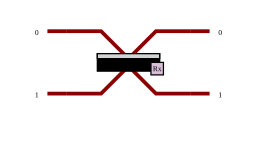

In [12]:
def coincidence(theta):
  return pcvl.Circuit(2)//pcvl.BS(theta = theta)

display(pcvl.pdisplay(coincidence(np.pi/2)))

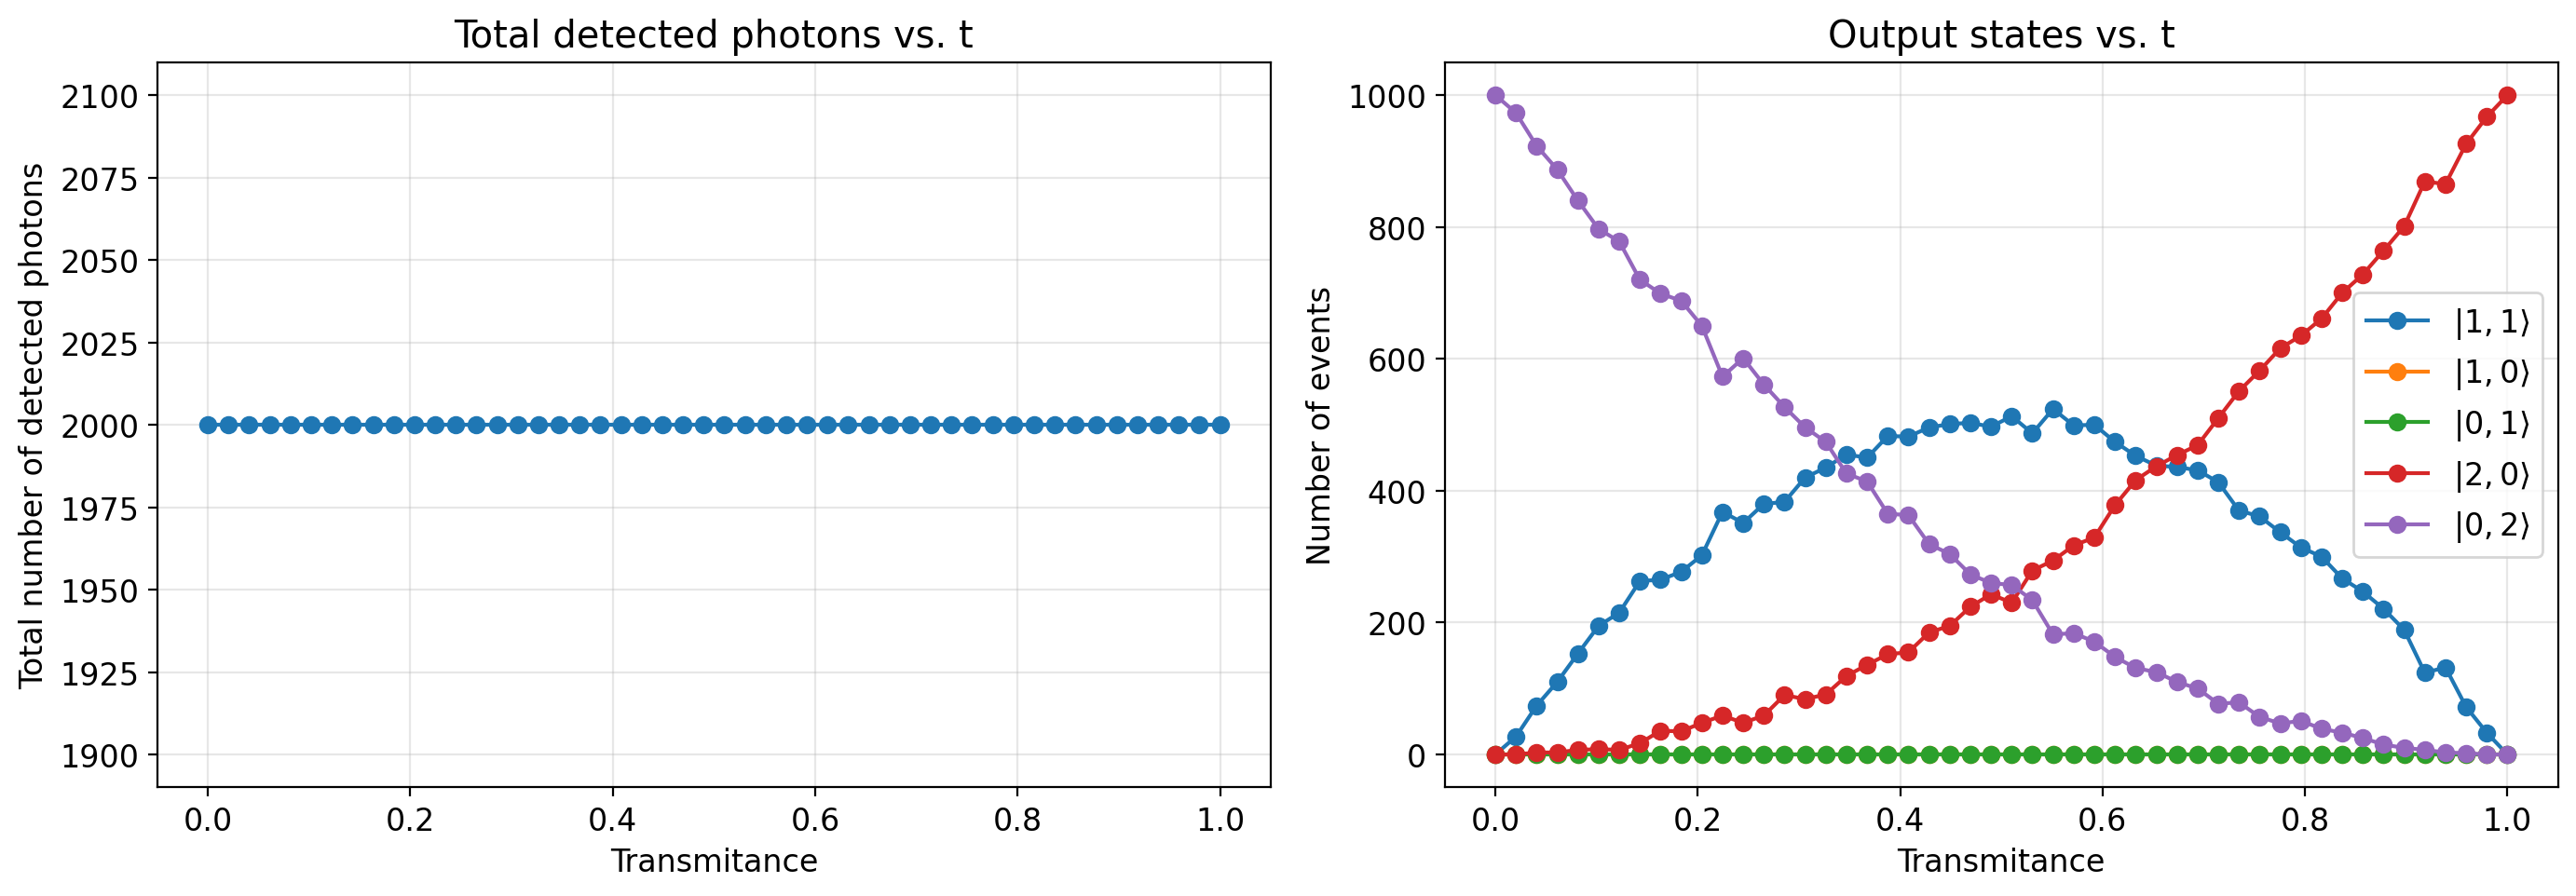

In [ ]:
# Beam splitter defined from transmitance
def coincidence(r):
    return pcvl.Circuit(2) // pcvl.BS(pcvl.BS.r_to_theta(r))


# Reflectivity range
rs = np.linspace(0., 1, 50)

# Transmission
ts = 1 - rs

state = pcvl.BasicState('|2,0>')

result = []

n_samples = 1000

# Total number of detected photons for each theta
total_photons = []

for t in ts:

    proc = pcvl.Processor(
        "SLOS",
        coincidence(t),
        noise=pcvl.NoiseModel(brightness=1)
    )

    proc.with_input(state)

    proc.min_detected_photons_filter(0)

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0,
        '20': 0,
        '02': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

        elif sample == pcvl.BasicState('|2,0>'):
            counts['20'] += 1

        elif sample == pcvl.BasicState('|0,2>'):
            counts['02'] += 1

    result.append(counts)

    # Total number of detected photons for this theta
    N_photons = (
        counts['01']
        + counts['10']
        + 2*counts['11']
        + 2*counts['20']
        + 2*counts['02']
    )

    total_photons.append(N_photons)


# ---------------------------------------------------------
# Extract the individual counts
# ---------------------------------------------------------

n01 = [r['01'] for r in result]
n10 = [r['10'] for r in result]
n11 = [r['11'] for r in result]
n20 = [r['20'] for r in result]
n02 = [r['02'] for r in result]


# ---------------------------------------------------------
# Create two subplots
# ---------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Total number of photons
# ---------------------------------------------------------

ax1.plot(
    ts,
    total_photons,
    marker='o'
)

ax1.set_xlabel(r'Transmitance')
ax1.set_ylabel('Total number of detected photons')
ax1.set_title('Total detected photons vs. t')

ax1.grid(True)


# ---------------------------------------------------------
# Plot 2: Individual output states
# ---------------------------------------------------------

ax2.plot(
    ts,
    n11,
    marker='o',
    label=r'$|1,1\rangle$'
)

ax2.plot(
    ts,
    n10,
    marker='o',
    label=r'$|1,0\rangle$'
)

ax2.plot(
    ts,
    n01,
    marker='o',
    label=r'$|0,1\rangle$'
)

ax2.plot(
    ts,
    n20,
    marker='o',
    label=r'$|2,0\rangle$'
)

ax2.plot(
    ts,
    n02,
    marker='o',
    label=r'$|0,2\rangle$'
)

ax2.set_xlabel(r'Transmitance')
ax2.set_ylabel('Number of events')
ax2.set_title('Output states vs. t')

ax2.grid(True)
ax2.legend()


plt.tight_layout()
plt.show()

As expected for the PNR the number of counts is always the same, eventhough the states change as we alter the transmitance. We also dont see states $|1,0\rangle$ and $|0,1\rangle$ because we assume there are no losses.


Now we would like to check how the same thing works for the APD.

We will plot the photon number given by the detectors and correct it using the coincidence counts.

The correction factor (from the article *Characterizing light intensities of continuous photon fluxes*) due to the binary saturation problem is given by :

$$
M = (\frac{T}{2R} + \frac{R}{2T}) * C
$$

Where M is the corrected amount we need to add and C are the coincidences (assuming perfect efficiency).

So in order for us to get the same number of photon counts when using an APD we simply need to:
$$
T_{PNR} = T_{APD} + M
$$

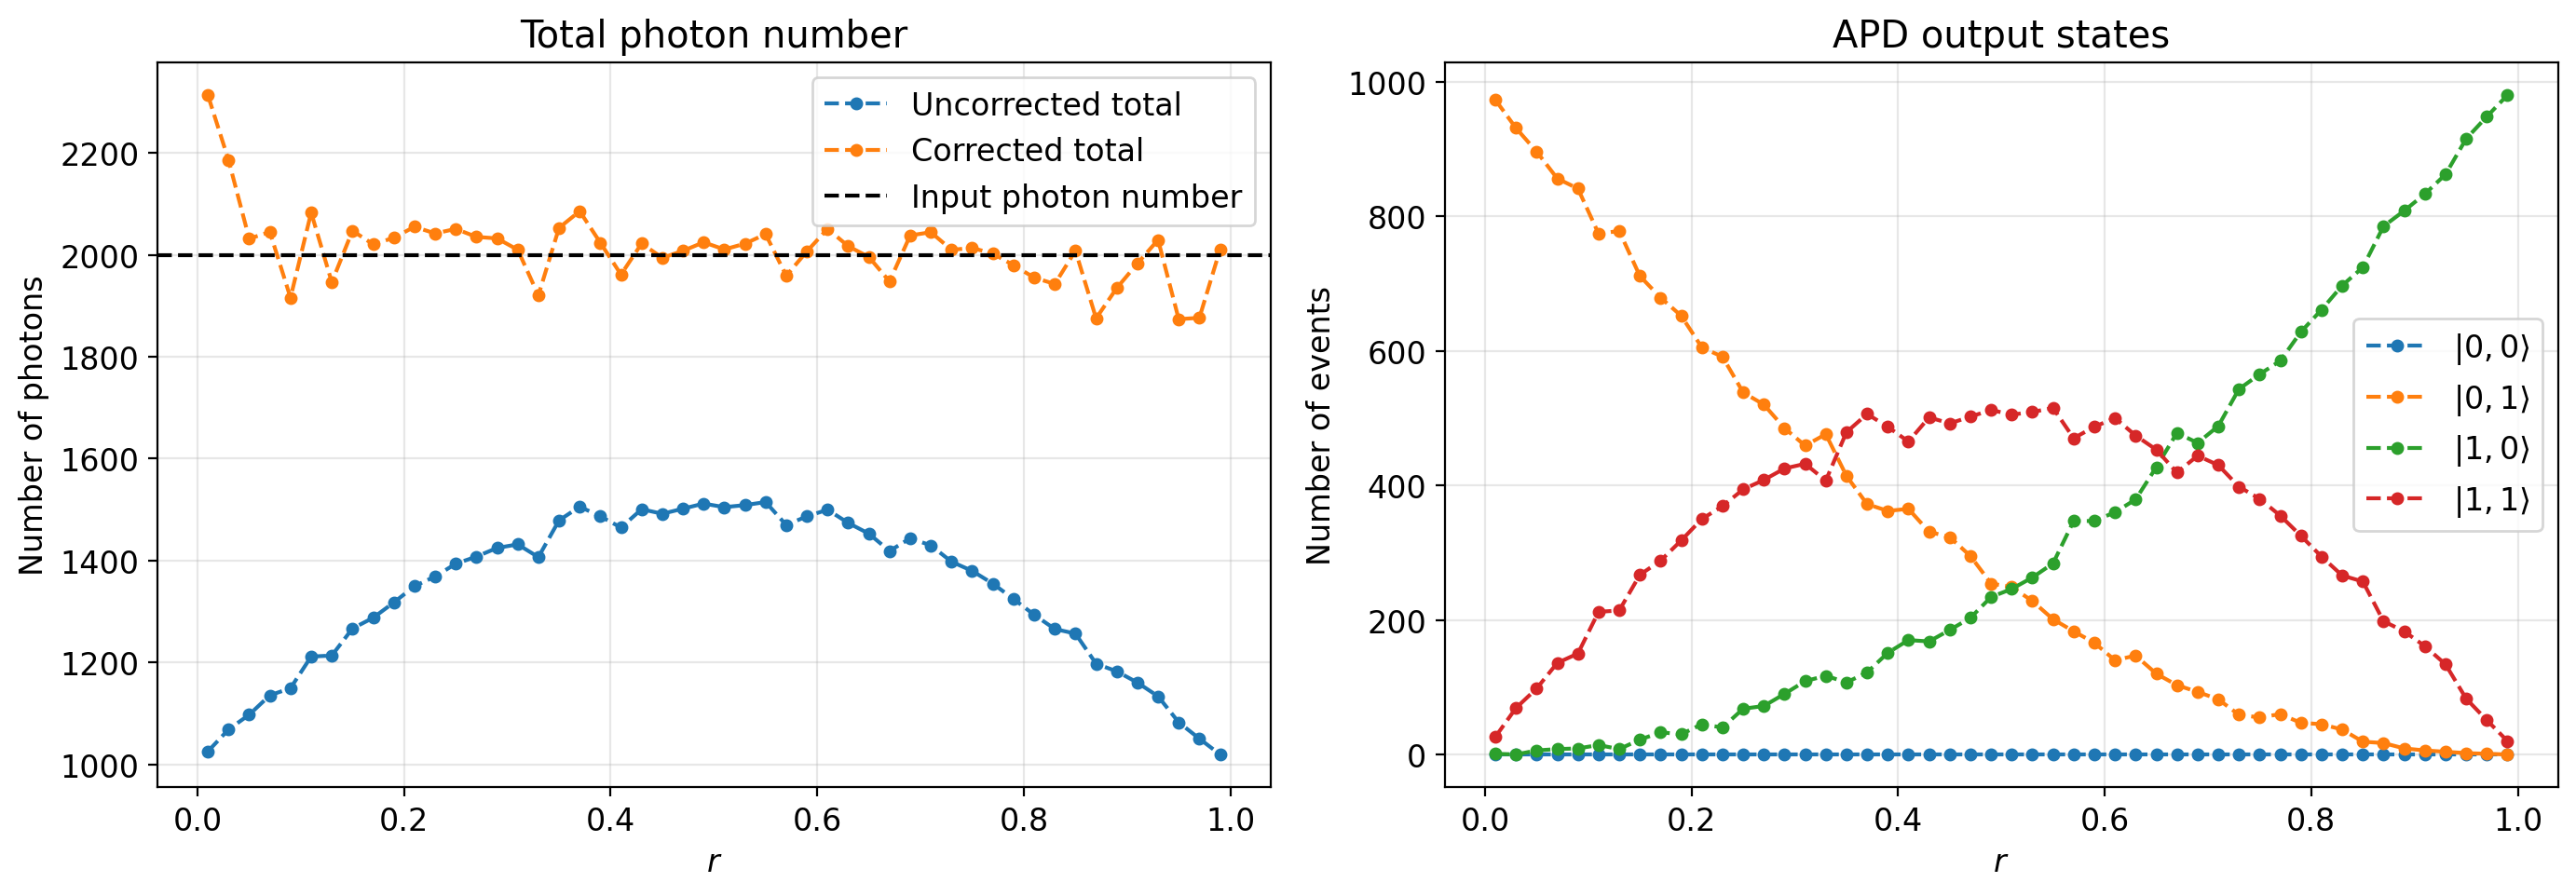

In [ ]:
state = pcvl.BasicState('|2,0>')
result = []

n_samples = 1000

# Reflectivity range
rs = np.linspace(0.01, 0.99, 50)

# Total number of detected photons/clicks
total_photons_apd = []

# Corrected number of photons
corrected_photons = []

for r in rs:

    proc = pcvl.Processor(
        "SLOS",
        coincidence(r),
        noise=pcvl.NoiseModel(brightness=1.)
    )

    proc.with_input(state)

    proc.min_detected_photons_filter(0)

    # APD / threshold detectors
    proc.add(0, pcvl.Detector.threshold())
    proc.add(1, pcvl.Detector.threshold())

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    # APD can only give 0 or 1 in each mode
    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

    result.append(counts)

    # Number of detected photons/clicks
    N_photons = (
        counts['01']
        + counts['10']
        + 2 * counts['11']
    )

    # Coincidences
    C = counts['11']
    t = 1 - r

    # Correction
    M = (t / (2 * r) + r / (2 * t)) * C

    total_photons_apd.append(N_photons + M)
    corrected_photons.append(M)


# Convert to numpy arrays
total_photons_apd = np.array(total_photons_apd)
corrected_photons = np.array(corrected_photons)


# =========================================================
# Additional quantities for plotting
# =========================================================

# Uncorrected total number of photons
uncorrected_photons = np.array([
    counts['01'] + counts['10'] + 2 * counts['11']
    for counts in result
])

# Individual states
n00 = np.array([counts['00'] for counts in result])
n01 = np.array([counts['01'] for counts in result])
n10 = np.array([counts['10'] for counts in result])
n11 = np.array([counts['11'] for counts in result])


# =========================================================
# Plots
# =========================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Uncorrected and corrected total photons
# ---------------------------------------------------------

ax1.plot(
    rs,
    uncorrected_photons,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Uncorrected total'
)

ax1.plot(
    rs,
    total_photons_apd,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Corrected total'
)

# True number of photons entering the circuit
ax1.axhline(
    2 * n_samples,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Input photon number'
)

ax1.set_xlabel(r'$r$')
ax1.set_ylabel('Number of photons')
ax1.set_title('Total photon number')

ax1.grid(True, alpha=0.3)
ax1.legend()


# ---------------------------------------------------------
# Plot 2: APD output states
# ---------------------------------------------------------

ax2.plot(
    rs,
    n00,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,0\rangle$'
)

ax2.plot(
    rs,
    n01,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,1\rangle$'
)

ax2.plot(
    rs,
    n10,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,0\rangle$'
)

ax2.plot(
    rs,
    n11,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,1\rangle$'
)

ax2.set_xlabel(r'$r$')
ax2.set_ylabel('Number of events')
ax2.set_title('APD output states')

ax2.grid(True, alpha=0.3)
ax2.legend()


plt.tight_layout()
plt.show()

As we can see (in the **blue** line) the number of photons measured by an APD is quite lower then the expected number of photons (line --). This is a consequence of not being able to measure $|2,0\rangle$ and confusing it with $|1,0\rangle$ (as we can see on the graph in the right: there are no two photon states, only one photon states that we know should not exist). However by adding the correction factor $M$ we recover the total number of expected photons, as seen in the **orange** line. 

Although there are some fluctuation, which may be expected since the correction factor is based on the Coincidence counts which fluctuate in each run and maybe because of numerical uncertanties given that $r$ and $t$ are floating numbers. Remember we are sampling in order to get these results! If we ran this instead of 1000 times 100000 we would certanly get a much smoother result.

We can now even add detector efficiencies and our correction factor becomes:

$$
M = (\frac{\eta_1T}{2\eta_2R} + \frac{\eta_2R}{\eta_12T}) * C
$$

In [13]:
eta1 = 0.9
eta2 = 0.9

### Although we can obviously set different eta's, it is better for the visualization purpose to keep them the same.
### This guarantees that we always have a easy to calculate expected total number counts.
### if they were different as we changed the transmitance the number count would increase.
## this is not a problem!! But just to keep a pretty graph I will keep the efficiencies the same.

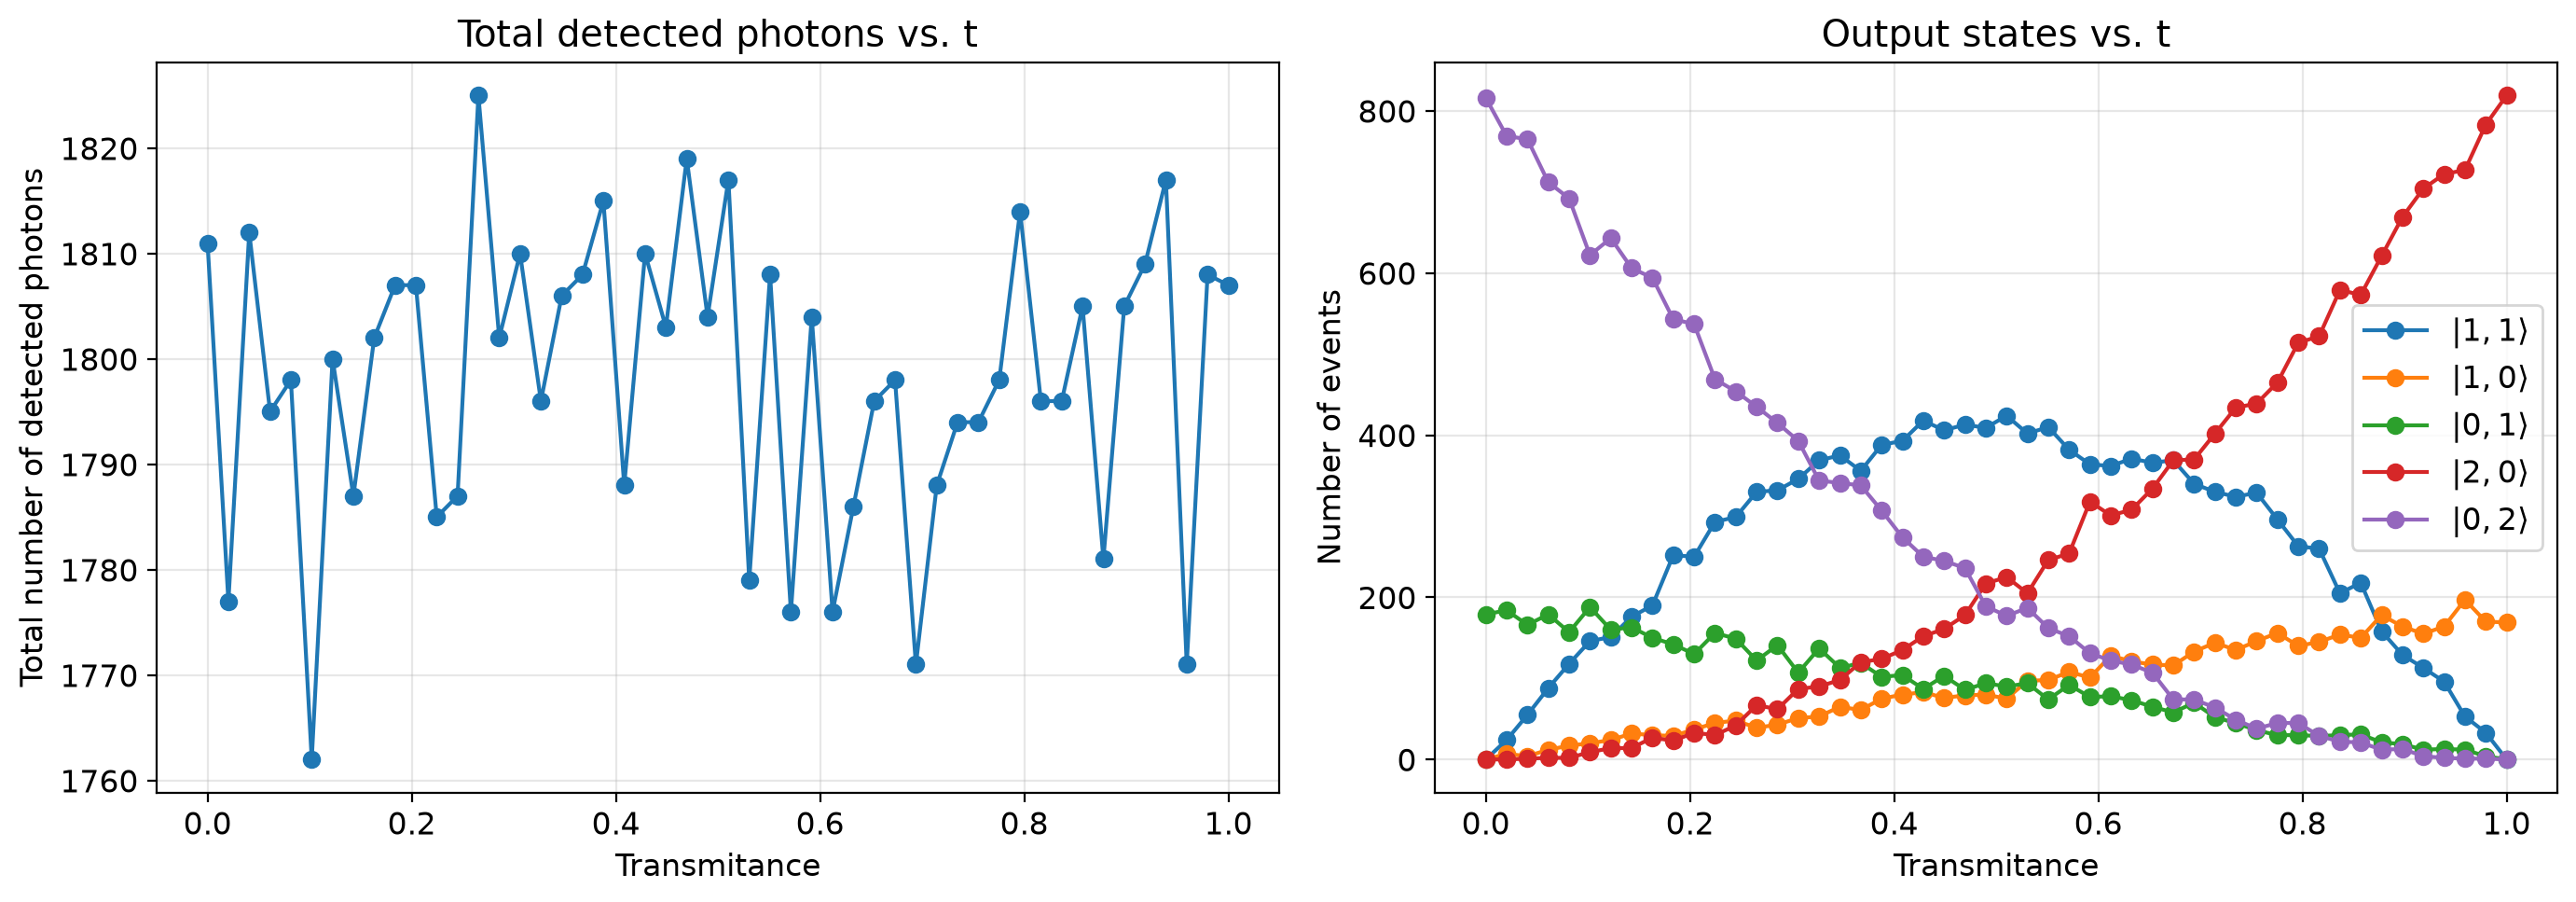

In [14]:
# Beam splitter defined from transmitance
def coincidence(r):
    return pcvl.Circuit(2) // pcvl.BS(pcvl.BS.r_to_theta(r))


# Reflectivity range
rs = np.linspace(0., 1, 50)

# Transmission
ts = 1 - rs

state = pcvl.BasicState('|2,0>')

result = []

n_samples = 1000

# Total number of detected photons for each theta
total_photons = []

for t in ts:

    proc = pcvl.Processor(
        "SLOS",
        coincidence(t),
        noise=pcvl.NoiseModel(brightness=1)
    )

    detector1 = pcvl.Detector.pnr() # PNR
    detector1.efficiency = eta1 # efficiency

    detector2 = pcvl.Detector.pnr() # PNR
    detector2.efficiency = eta2 # efficiency

    proc.add(0, detector1)
    proc.add(1,detector2)

    proc.with_input(state)

    proc.min_detected_photons_filter(0)

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0,
        '20': 0,
        '02': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

        elif sample == pcvl.BasicState('|2,0>'):
            counts['20'] += 1

        elif sample == pcvl.BasicState('|0,2>'):
            counts['02'] += 1

    result.append(counts)

    # Total number of detected photons for this theta
    N_photons = (
        counts['01']
        + counts['10']
        + 2*counts['11']
        + 2*counts['20']
        + 2*counts['02']
    )

    total_photons.append(N_photons)


# ---------------------------------------------------------
# Extract the individual counts
# ---------------------------------------------------------

n01 = [r['01'] for r in result]
n10 = [r['10'] for r in result]
n11 = [r['11'] for r in result]
n20 = [r['20'] for r in result]
n02 = [r['02'] for r in result]


# ---------------------------------------------------------
# Create two subplots
# ---------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Total number of photons
# ---------------------------------------------------------

ax1.plot(
    ts,
    total_photons,
    marker='o'
)

ax1.set_xlabel(r'Transmitance')
ax1.set_ylabel('Total number of detected photons')
ax1.set_title('Total detected photons vs. t')

ax1.grid(True)


# ---------------------------------------------------------
# Plot 2: Individual output states
# ---------------------------------------------------------

ax2.plot(
    ts,
    n11,
    marker='o',
    label=r'$|1,1\rangle$'
)

ax2.plot(
    ts,
    n10,
    marker='o',
    label=r'$|1,0\rangle$'
)

ax2.plot(
    ts,
    n01,
    marker='o',
    label=r'$|0,1\rangle$'
)

ax2.plot(
    ts,
    n20,
    marker='o',
    label=r'$|2,0\rangle$'
)

ax2.plot(
    ts,
    n02,
    marker='o',
    label=r'$|0,2\rangle$'
)

ax2.set_xlabel(r'Transmitance')
ax2.set_ylabel('Number of events')
ax2.set_title('Output states vs. t')

ax2.grid(True)
ax2.legend()


plt.tight_layout()
plt.show()

In [15]:
eta1 = 0.9; eta2 = 0.9

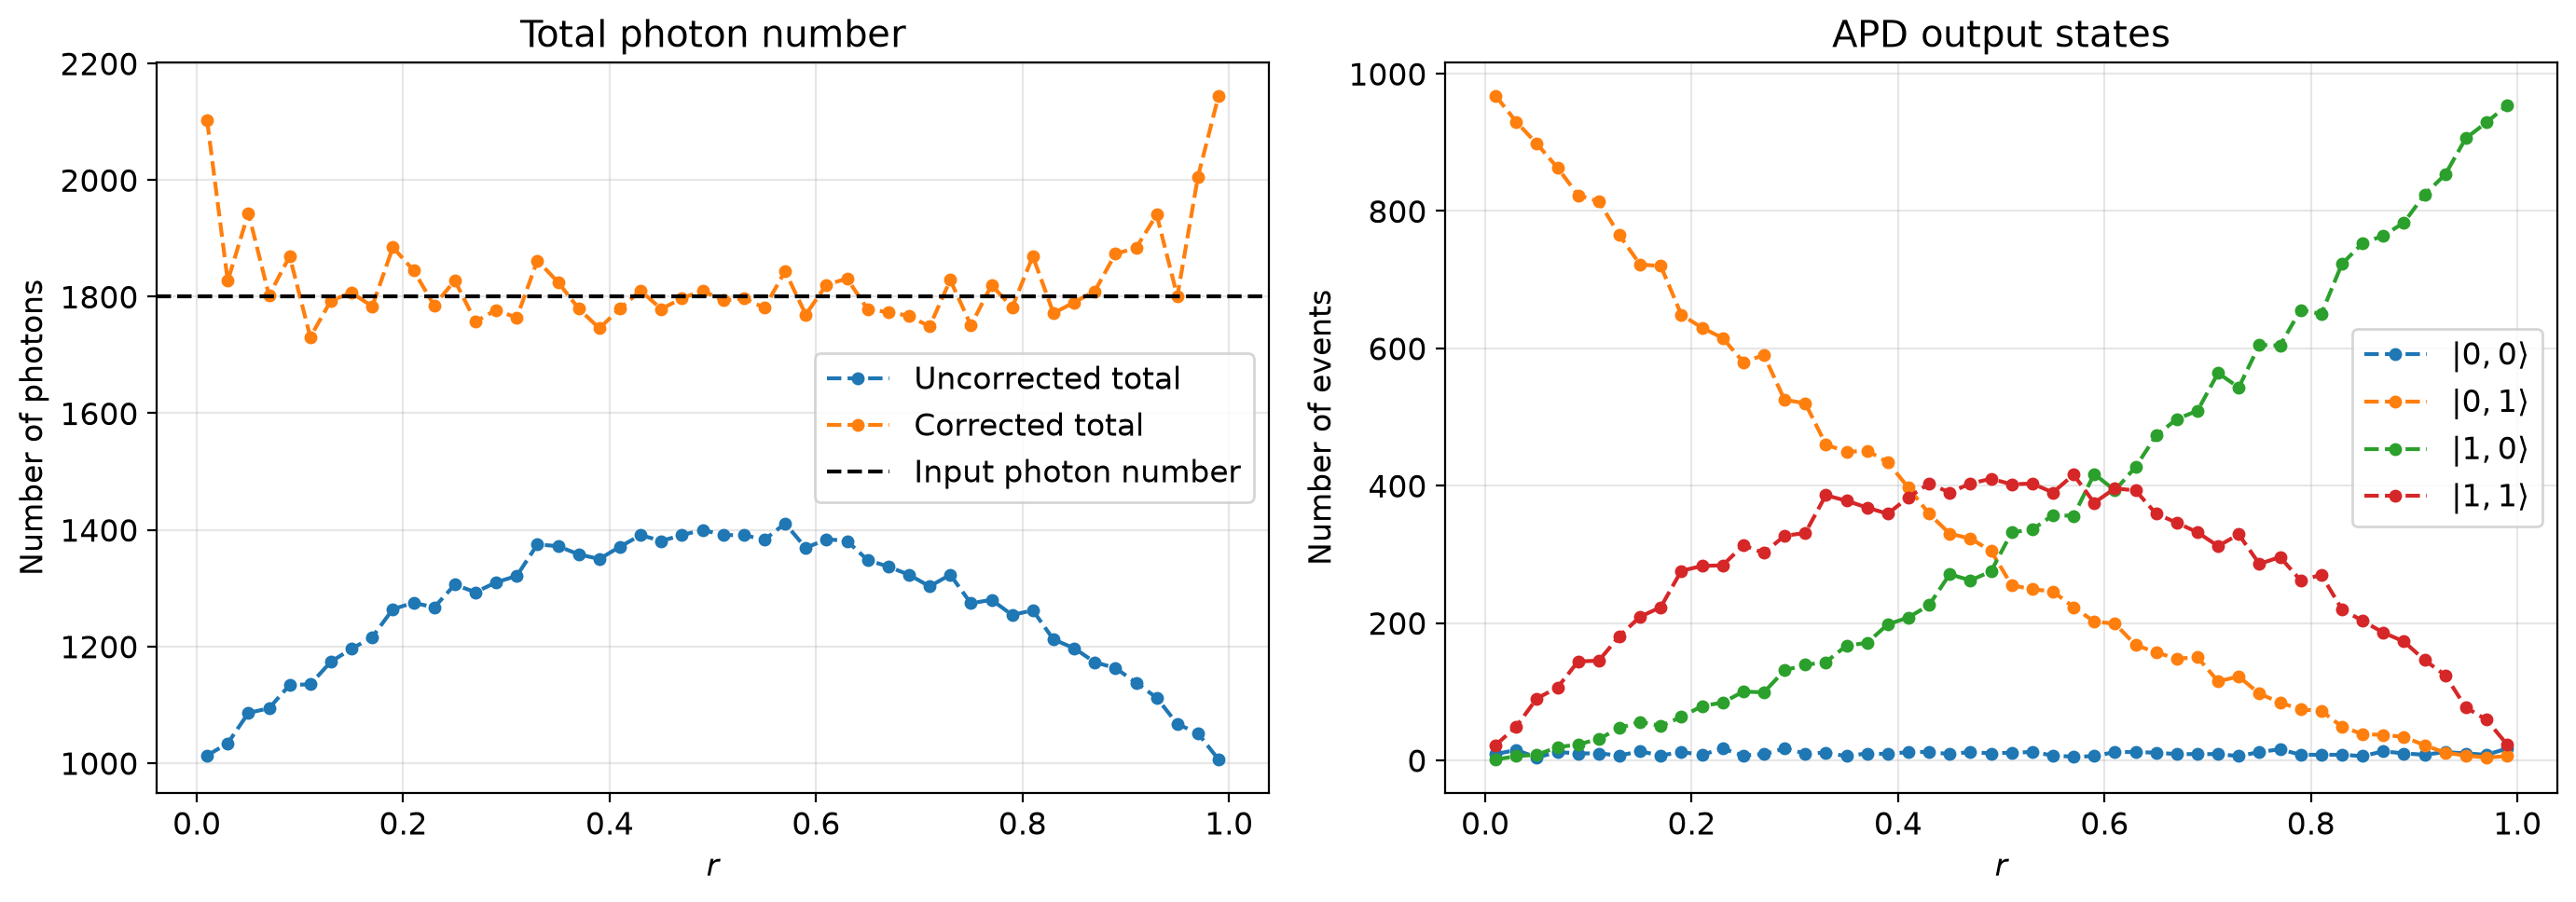

In [16]:
state = pcvl.BasicState('|2,0>')
result = []

n_samples = 1000

# Reflectivity range
rs = np.linspace(0.01, 0.99, 50)

# Total number of detected photons/clicks
total_photons_apd = []

# Corrected number of photons
corrected_photons = []

for r in rs:

    proc = pcvl.Processor(
        "SLOS",
        coincidence(r),
        noise=pcvl.NoiseModel(brightness=1.)
    )

    proc.with_input(state)


    detector1 = pcvl.Detector.threshold() # PNR
    detector1.efficiency = eta1 # efficiency
    proc.add(0, detector1)

    detector2= pcvl.Detector.threshold() # PNR
    detector2.efficiency = eta2 # efficiency
    proc.add(1, detector2)

    proc.min_detected_photons_filter(0)

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    # APD can only give 0 or 1 in each mode
    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

    result.append(counts)

    # Number of detected photons/clicks
    N_photons = (
        counts['01']
        + counts['10']
        + 2 * counts['11']
    )

    # Coincidences
    C = counts['11']
    t = 1 - r

    # Correction
    M = ((t*eta1) / (2*eta2 * r) + (eta2*r) / (2*eta1 * t)) * C

    total_photons_apd.append(N_photons + M)
    corrected_photons.append(M)


# Convert to numpy arrays
total_photons_apd = np.array(total_photons_apd)
corrected_photons = np.array(corrected_photons)


# =========================================================
# Additional quantities for plotting
# =========================================================

# Uncorrected total number of photons
uncorrected_photons = np.array([
    counts['01'] + counts['10'] + 2 * counts['11']
    for counts in result
])

# Individual states
n00 = np.array([counts['00'] for counts in result])
n01 = np.array([counts['01'] for counts in result])
n10 = np.array([counts['10'] for counts in result])
n11 = np.array([counts['11'] for counts in result])


# =========================================================
# Plots
# =========================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Uncorrected and corrected total photons
# ---------------------------------------------------------

ax1.plot(
    rs,
    uncorrected_photons,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Uncorrected total'
)

ax1.plot(
    rs,
    total_photons_apd,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Corrected total'
)

# True number of photons entering the circuit
ax1.axhline(
    2 * n_samples*eta1,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Input photon number'
)

ax1.set_xlabel(r'$r$')
ax1.set_ylabel('Number of photons')
ax1.set_title('Total photon number')

ax1.grid(True, alpha=0.3)
ax1.legend()


# ---------------------------------------------------------
# Plot 2: APD output states
# ---------------------------------------------------------

ax2.plot(
    rs,
    n00,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,0\rangle$'
)

ax2.plot(
    rs,
    n01,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,1\rangle$'
)

ax2.plot(
    rs,
    n10,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,0\rangle$'
)

ax2.plot(
    rs,
    n11,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,1\rangle$'
)

ax2.set_xlabel(r'$r$')
ax2.set_ylabel('Number of events')
ax2.set_title('APD output states')

ax2.grid(True, alpha=0.3)
ax2.legend()


plt.tight_layout()
plt.show()

## Work in progress......

Great! Works again. We have shown that for our premisses the correction factor works pretty well! However our real problem is a bit different. We do not have such simple states with two photons entering, always indistinguishably and with PNR detectors to compare. But we are slowly getting closer to it. Let's keep progressively working towards a more realistic simulation of our problem. 



SPDC is a non-linear process which produces multi-pair emissions, indistinguishable in space and time, from a coherent pump. This state can be described by the state-vector:
$$
|\psi\rangle_{SPDC} = (1 - \lambda^2)\sum_{n = 0}^\infty \lambda^{2n} |n\rangle_s|n\rangle_i
$$
As we can see the number of photons that can be produced goes up to infinity, if it were not for the coeficients, which get smaller and smaller as we increase the number of photons. In general, we are interested in tuning $\lambda$ so that we can favour the production of states $|1\rangle_s|1\rangle_i$ and higher order pairs are small in comparison. 

Now that we have understood that we need to take into account the looses due to binary saturation we can take a look into what happens when we cut half of the SPDC beam and are left with a thermal photon statistics. 

We want to know how many more photons we need to put in the thermal state in order to get the same amount for SPDC. When we are using APDs we must take into account our binary saturation correction to know the full number of photons for the SPDC.

(THIS PART WILL BE MORE DETAILED).

### Daqui pra baixo ainda estou incerto a respeito dos resultados e como interpretá-los.

Problemas: 
1. Definir o estado descrito acima para o SPDC significa que um foton entra por um modo, enquanto o outro entra pelo segundo modo. Isso faz com que as coincidências sejam minimas quando r = 0.5 e máximas nos extremos o que faz a correção explodir. Acredito que esse não seja um problema no caso real, porque os fótons entram pela mesma fibra, sendo separados pelo BS, de tal forma que as coincidências seriam máximas em r=0.5. PAra corrigir isso introduzi um BS com r = 0.5 no começo, para mandar os estados |1,1> em |2,0> e reorganizar o máximo de coincidências. Apesar de achar que a ideia está bem direcionada, não sei se isso transforma o nosso problema em outra coisa.

2. Me parece que correção introduzida, é meio que em primeira ordem e para coincidências para mais de 1 fóton talvez seria outro fator, porém não conseguimos fazer essa distinção, então vamos sempre superestimar. 



In [40]:
N_MAX = 4   # truncation: keep terms up to |N_MAX, N_MAX> (fine at lambda = 0.4;
            # raise it as lambda -> 1, or the tail you drop will lie to you)

def tmsv(lam: float, N_MAX = 4,n_extra_modes: int = 0) -> pcvl.StateVector:
    """Two-mode squeezed vacuum sum_n lambda^n |n,n>, truncated at N_MAX.

    Parameters
    ----------
    lam : pair amplitude lambda = tanh r in [0, 1) (dimensionless)
    n_extra_modes : number of extra empty modes appended (for loss ancillas)

    Perceval normalizes StateVectors automatically.
    """
    lam = float(lam)   # plain float: numpy scalars confuse StateVector algebra
    sv = pcvl.StateVector()
    for n in range(N_MAX + 1):
        sv += (lam ** n) * pcvl.StateVector(
            pcvl.BasicState([n, n] + [0] * n_extra_modes))
    return sv

# Sanity check: photon-number distribution of the source at lambda = 0.4
lam = 0.4
sim = Simulator(SLOSBackend())
sim.set_circuit(pcvl.Circuit(2))          # empty circuit: just look at the state
dist = sim.probs(tmsv(lam))

print("P(n_signal, n_idler):")
for st, p in sorted(dist.items(), key=lambda kv: -kv[1]):
    if p > 1e-4:
        print(f"  {st}: {p:.4f}")
print("\nonly diagonal terms |n,n> - perfect pair correlation")

P(n_signal, n_idler):
  |0,0>: 0.8401
  |1,1>: 0.1344
  |2,2>: 0.0215
  |3,3>: 0.0034
  |4,4>: 0.0006

only diagonal terms |n,n> - perfect pair correlation


In [48]:
eta1 = 1.;eta2=1.

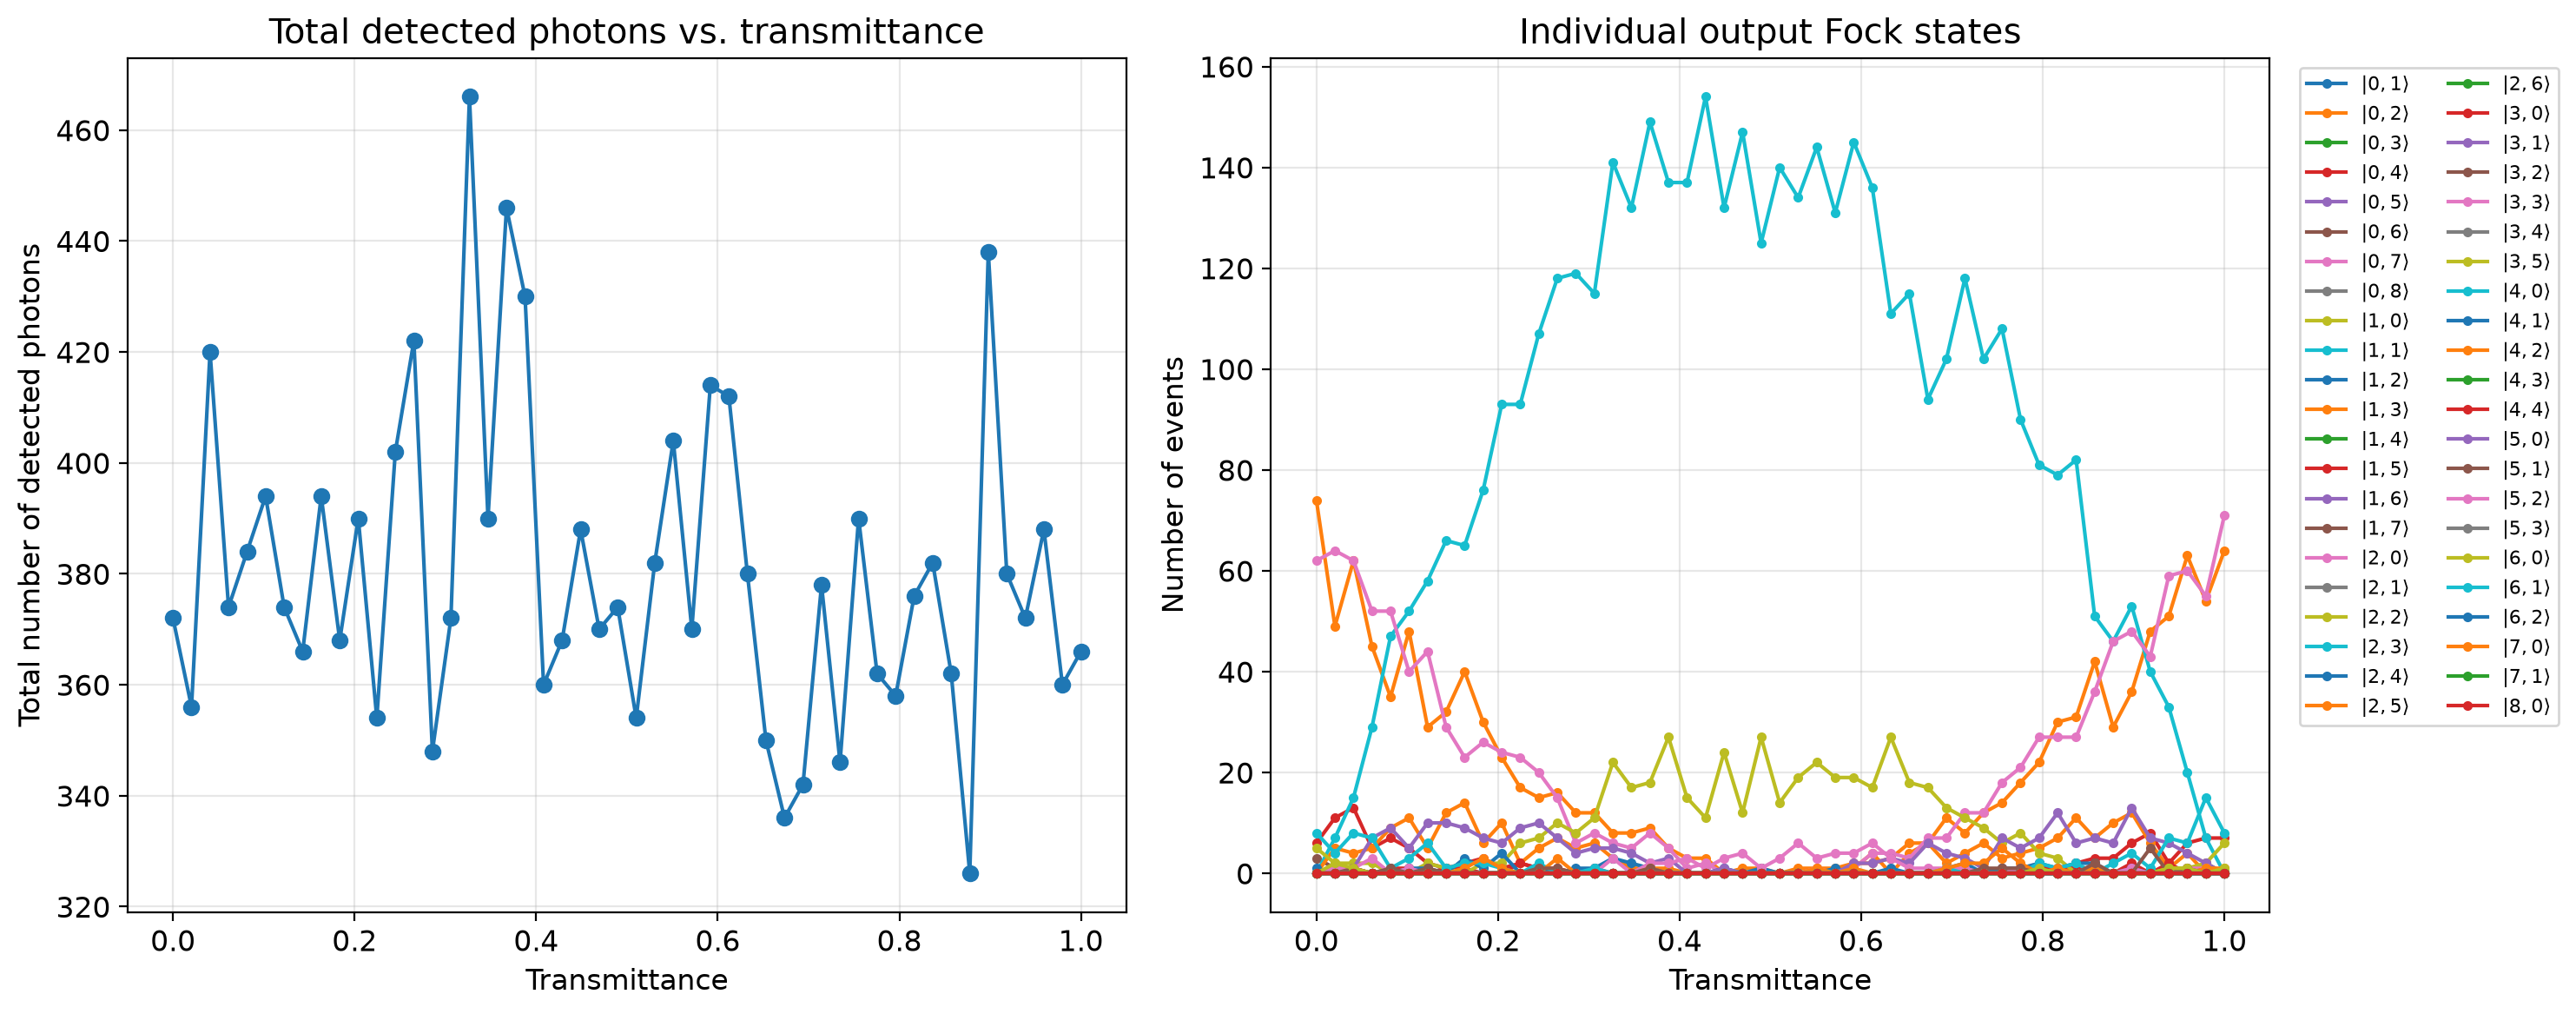

In [79]:
eta1 = 1.
eta2 = 1.

def coincidence_mod(r):
    return pcvl.Circuit(2) // pcvl.BS(
        theta=pcvl.BS.r_to_theta(0.5)
    ) // pcvl.BS(
        pcvl.BS.r_to_theta(r)
    )

# this added beam splitters guarantee that the maximum coincidences
# happen when r = 0.5 and not in the beginning.
# this reproduces more realistically our own experiment.


N_MAX = 4
lam = 0.4


state = tmsv(lam, N_MAX=3)

n_samples = 1000


# ------------------------------------------------------------
# All physically possible detected states
#
# N_MAX is the maximum number of SPDC PAIRS.
#
# Therefore, the maximum total number of photons is:
#
#       2 * N_MAX
#
# For N_MAX = 3, the source contains at most 6 photons:
#
#       |0,0>, |1,1>, |2,2>, |3,3>
#
# Since the optical circuit is passive, the output must satisfy:
#
#       n1 + n2 <= 2 * N_MAX
# ------------------------------------------------------------

physical_states = [
    (n1, n2)
    for n1 in range(2 * N_MAX + 1)
    for n2 in range(2 * N_MAX + 1)
    if n1 + n2 <= 2 * N_MAX
]


# ------------------------------------------------------------
# Containers for simulation results
# ------------------------------------------------------------

result = []

# Total number of detected photons for each theta
total_photons = []

# Total number of detection EVENTS for each theta
total_events = []


# ============================================================
# RUN SIMULATION FOR EACH TRANSMITTANCE
# ============================================================

for t in ts:

    # --------------------------------------------------------
    # Processor
    # --------------------------------------------------------

    proc = pcvl.Processor(
        "SLOS",
        coincidence_mod(t),
        noise=pcvl.NoiseModel(brightness=1)
    )


    # --------------------------------------------------------
    # PNR detectors
    # --------------------------------------------------------

    detector1 = pcvl.Detector.pnr()
    detector1.efficiency = eta1

    detector2 = pcvl.Detector.pnr()
    detector2.efficiency = eta2

    proc.add(0, detector1)
    proc.add(1, detector2)


    # --------------------------------------------------------
    # Input state
    # --------------------------------------------------------

    proc.with_input(state)

    # Ignore vacuum events!!
    proc.min_detected_photons_filter(0)


    # --------------------------------------------------------
    # Sampling
    # --------------------------------------------------------

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']


    # --------------------------------------------------------
    # Initialise counters for ALL physical Fock states
    # --------------------------------------------------------

    counts = {
        (n1, n2): 0
        for n1, n2 in physical_states
    }


    # --------------------------------------------------------
    # Count ALL sampled states automatically
    # --------------------------------------------------------

    for sample in samples:

        n1 = int(sample[0])
        n2 = int(sample[1])

        key = (n1, n2)

        if key in counts:
            counts[key] += 1


    result.append(counts)


    # --------------------------------------------------------
    # Total number of detected photons
    #
    # Every event |n1,n2> contributes n1+n2 photons.
    # --------------------------------------------------------

    N_photons = sum(
        (n1 + n2) * counts[(n1, n2)]
        for n1, n2 in physical_states
    )

    total_photons.append(N_photons)


    # --------------------------------------------------------
    # Total number of events
    # --------------------------------------------------------

    total_events.append(
        sum(counts.values())
    )


# ============================================================
# EXTRACT COUNTS OF EACH INDIVIDUAL FOCK STATE
# ============================================================

state_counts = {}

for n1, n2 in physical_states:

    state_counts[(n1, n2)] = [
        r[(n1, n2)]
        for r in result
    ]


# ============================================================
# GROUP EVENTS BY TOTAL DETECTED PHOTON NUMBER
#
# N_MAX = 3 means up to 3 PAIRS,
# therefore up to 6 total photons.
#
# N = 0:
#   |0,0>
#
# N = 1:
#   |1,0>, |0,1>
#
# N = 2:
#   |2,0>, |1,1>, |0,2>
#
# ...
#
# N = 6:
#   |6,0>, |5,1>, |4,2>, |3,3>,
#   |2,4>, |1,5>, |0,6>
# ============================================================

photon_number_counts = {
    N: []
    for N in range(2 * N_MAX + 1)
}


for r in result:

    for N in range(2 * N_MAX + 1):

        count_N = sum(
            r[(n1, n2)]
            for n1, n2 in physical_states
            if n1 + n2 == N
        )

        photon_number_counts[N].append(count_N)


for N in range(2 * N_MAX + 1):

    for n1, n2 in physical_states:

        if n1 + n2 == N:

            c = result[0][(n1, n2)]


# ============================================================
# PLOTS
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)


# ============================================================
# PLOT 1
# Total number of detected photons vs transmittance
# ============================================================

ax1.plot(
    ts,
    total_photons,
    marker='o'
)

ax1.set_xlabel('Transmittance')
ax1.set_ylabel('Total number of detected photons')
ax1.set_title(
    'Total detected photons vs. transmittance'
)

ax1.grid(True)


# ============================================================
# PLOT 2
# Individual output Fock states
# ============================================================

for n1, n2 in physical_states:

    # Skip vacuum to make the figure easier to read
    if n1 == 0 and n2 == 0:
        continue

    ax2.plot(
        ts,
        state_counts[(n1, n2)],
        marker='o',
        markersize=3,
        label=rf'$|{n1},{n2}\rangle$'
    )


ax2.set_xlabel('Transmittance')
ax2.set_ylabel('Number of events')

ax2.set_title(
    'Individual output Fock states'
)

ax2.grid(True)

ax2.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=8,
    ncol=2
)


# ------------------------------------------------------------
# Final formatting
# ------------------------------------------------------------

plt.tight_layout()

plt.show()

In [66]:
eta1 = 1.;eta2 = 1.

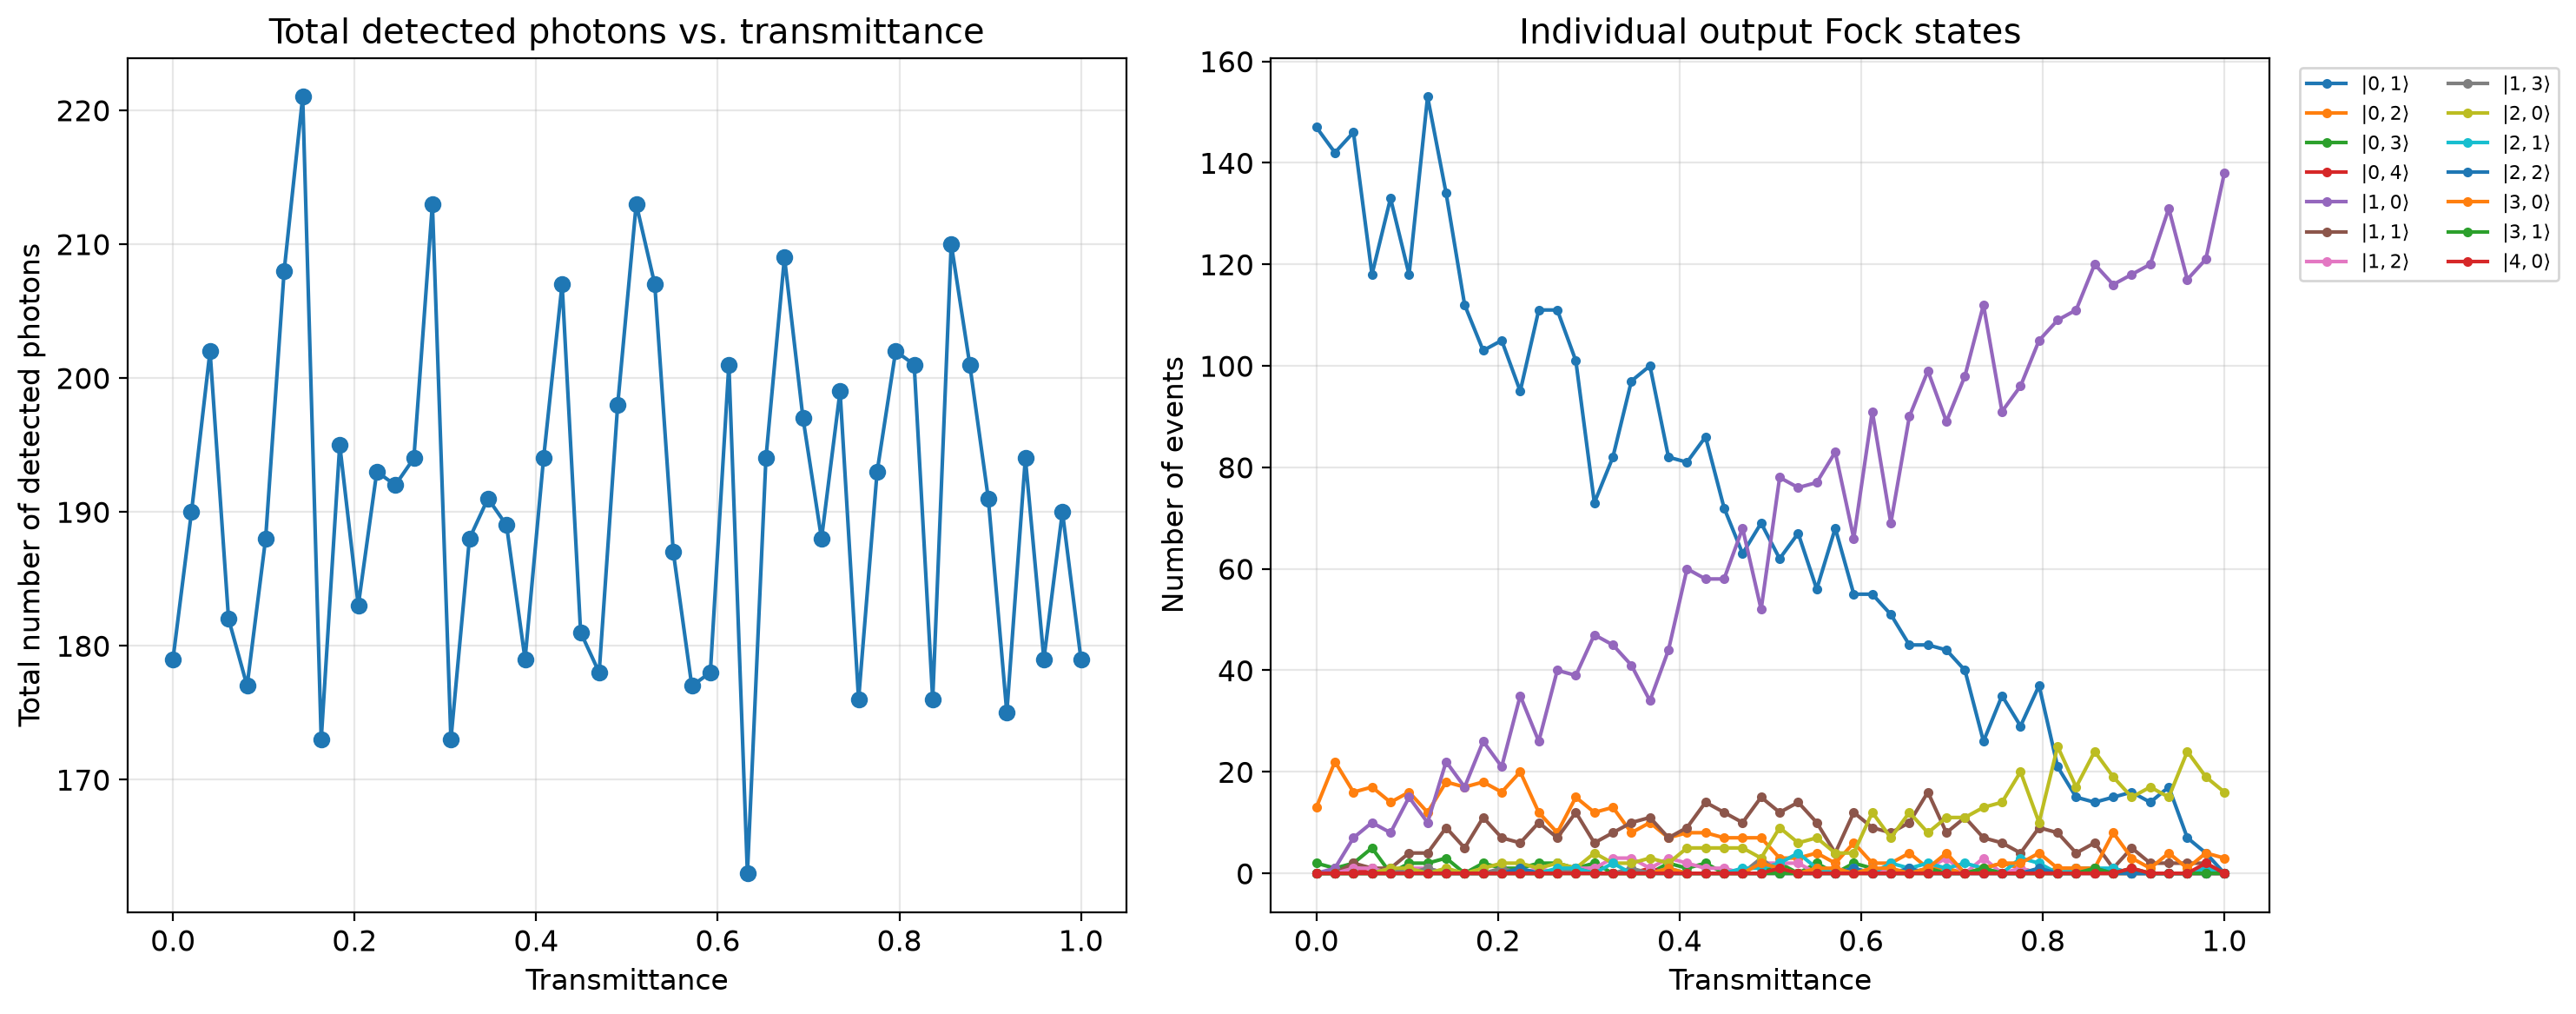

In [80]:

N_MAX = 4
lam = 0.4

# Assumes thermal_x_vacuum(lam) has already been defined
# and returns the mixed two-mode state
#
# rho = rho_thermal ⊗ |0><0|

state = thermal_x_vacuum(lam)

n_samples = 1000


# ------------------------------------------------------------
# All physically possible detected states
#
# Since the source contains at most N_MAX photons and the
# optical circuit is passive, we must have:
#
#       n1 + n2 <= N_MAX
#
# For N_MAX = 6 this gives 28 possible states.
# ------------------------------------------------------------

physical_states = [
    (n1, n2)
    for n1 in range(N_MAX + 1)
    for n2 in range(N_MAX + 1)
    if n1 + n2 <= N_MAX
]

    


# ------------------------------------------------------------
# Containers for simulation results
# ------------------------------------------------------------

result = []

# Total number of detected photons for each transmittance
total_photons = []

# Total number of detection EVENTS for each transmittance
total_events = []


# ============================================================
# RUN SIMULATION FOR EACH TRANSMITTANCE
# ============================================================

for t in ts:

    # --------------------------------------------------------
    # Processor
    # --------------------------------------------------------

    proc = pcvl.Processor(
        "SLOS",
        coincidence(t),
        noise=pcvl.NoiseModel(brightness=1)
    )


    # --------------------------------------------------------
    # PNR detectors
    # --------------------------------------------------------

    detector1 = pcvl.Detector.pnr()
    detector1.efficiency = eta1

    detector2 = pcvl.Detector.pnr()
    detector2.efficiency = eta2

    proc.add(0, detector1)
    proc.add(1, detector2)


    # --------------------------------------------------------
    # Input state
    # --------------------------------------------------------

    proc.with_input(state)

    # Ignore vaccum events!!
    proc.min_detected_photons_filter(0)


    # --------------------------------------------------------
    # Sampling
    # --------------------------------------------------------

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']


    # --------------------------------------------------------
    # Initialise counters for ALL physical Fock states
    # --------------------------------------------------------

    counts = {
        (n1, n2): 0
        for n1, n2 in physical_states
    }


    # --------------------------------------------------------
    # Count ALL sampled states automatically
    # --------------------------------------------------------

    for sample in samples:

        n1 = int(sample[0])
        n2 = int(sample[1])

        key = (n1, n2)

        if key in counts:
            counts[key] += 1

        else:
            # This should normally never happen if the circuit
            # is passive and the source contains <= N_MAX photons.
            print(
                f"Warning: detected unexpected state "
                f"|{n1},{n2}> at t = {t}"
            )


    result.append(counts)


    # --------------------------------------------------------
    # Total number of detected photons
    #
    # Every event |n1,n2> contributes n1+n2 photons.
    # --------------------------------------------------------

    N_photons = sum(
        (n1 + n2) * counts[(n1, n2)]
        for n1, n2 in physical_states
    )

    total_photons.append(N_photons)


    # --------------------------------------------------------
    # Total number of events
    # --------------------------------------------------------

    total_events.append(
        sum(counts.values())
    )


# ============================================================
# EXTRACT COUNTS OF EACH INDIVIDUAL FOCK STATE
# ============================================================

state_counts = {}

for n1, n2 in physical_states:

    state_counts[(n1, n2)] = [
        r[(n1, n2)]
        for r in result
    ]


# ============================================================
# GROUP EVENTS BY TOTAL DETECTED PHOTON NUMBER
#
# N = 0:
#   |0,0>
#
# N = 1:
#   |1,0>, |0,1>
#
# N = 2:
#   |2,0>, |1,1>, |0,2>
#
# ...
#
# N = 6:
#   |6,0>, |5,1>, |4,2>, |3,3>,
#   |2,4>, |1,5>, |0,6>
# ============================================================

photon_number_counts = {
    N: []
    for N in range(N_MAX + 1)
}


for r in result:

    for N in range(N_MAX + 1):

        count_N = sum(
            r[(n1, n2)]
            for n1, n2 in physical_states
            if n1 + n2 == N
        )

        photon_number_counts[N].append(count_N)


for N in range(N_MAX + 1):



    for n1, n2 in physical_states:

        if n1 + n2 == N:

            c = result[0][(n1, n2)]





# ============================================================
# PLOTS
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)


# ============================================================
# PLOT 1
# Total number of detected photons vs transmittance
# ============================================================

ax1.plot(
    ts,
    total_photons,
    marker='o'
)

ax1.set_xlabel('Transmittance')
ax1.set_ylabel('Total number of detected photons')
ax1.set_title(
    'Total detected photons vs. transmittance'
)

ax1.grid(True)


# ============================================================
# PLOT 2
# Individual output Fock states
# ============================================================

for n1, n2 in physical_states:

    # Skip vacuum to make the figure easier to read
    if n1 == 0 and n2 == 0:
        continue

    ax2.plot(
        ts,
        state_counts[(n1, n2)],
        marker='o',
        markersize=3,
        label=rf'$|{n1},{n2}\rangle$'
    )


ax2.set_xlabel('Transmittance')
ax2.set_ylabel('Number of events')

ax2.set_title(
    'Individual output Fock states'
)

ax2.grid(True)

ax2.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=8,
    ncol=2
)


# ============================================================
# PLOT 3
# Counts grouped by TOTAL photon number
# ============================================================


# ------------------------------------------------------------
# Final formatting
# ------------------------------------------------------------

plt.tight_layout()

plt.show()

Vemos que tem uma relacao entre de S_termico = 1/2(S_spdc). Faz sentido porque pegamos metade dos fotons e jogamos fora. Agora, sera que na APD a gente consegue recuperar isso. A gente vai ver que ate no termico nos perdemos algumas contagens. E o grande problema é que a correcao para o SPDC está overestimando.

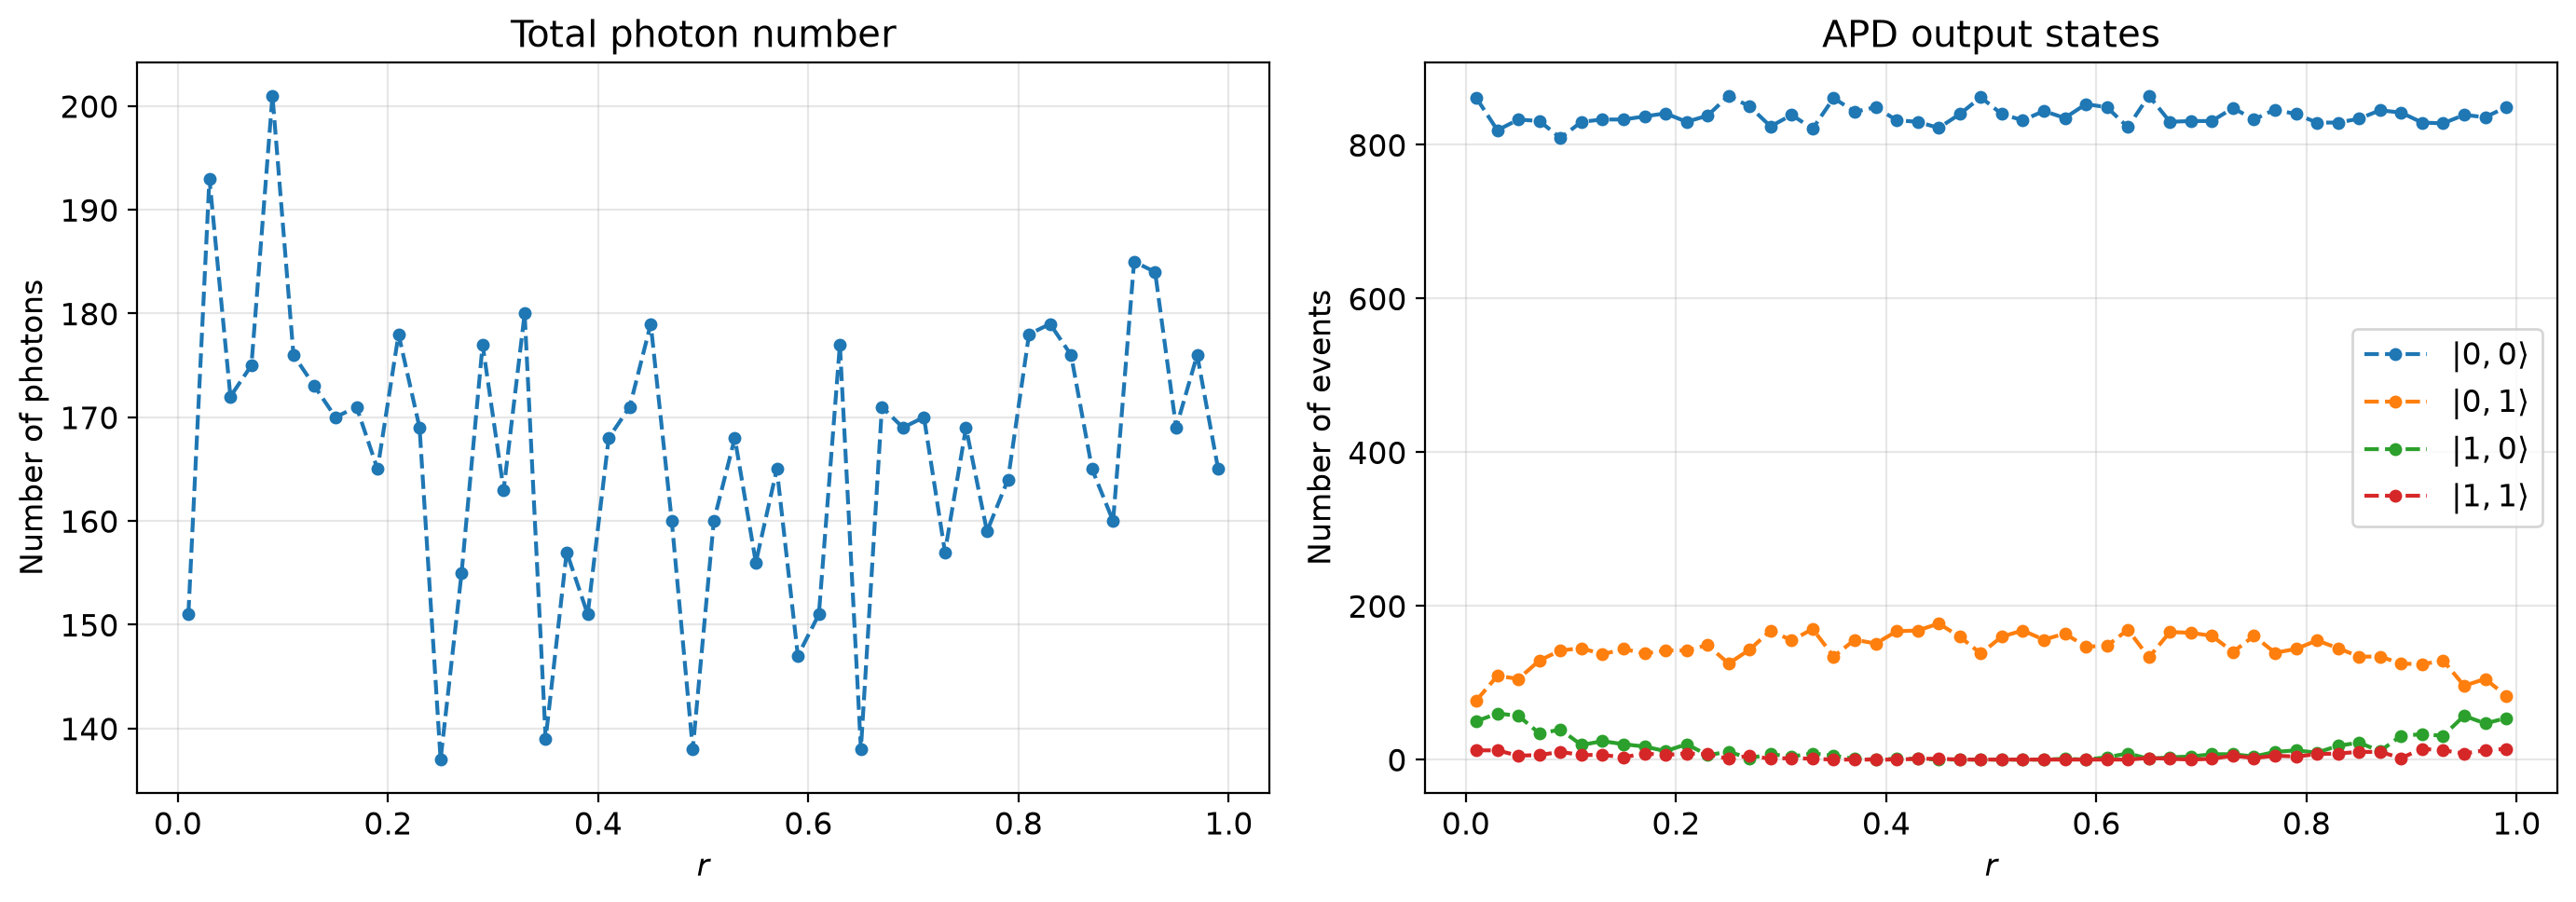

In [81]:
lam = 0.4
N_MAX = 4
state = thermal_x_vacuum(lam)
result = []

n_samples = 1000

# Reflectivity range
rs = np.linspace(0.01, 0.99, 50)

# Total number of detected photons/clicks
total_photons_apd = []

# Corrected number of photons
corrected_photons = []

for r in rs:

    proc = pcvl.Processor(
        "SLOS",
        coincidence_mod(r),
        noise=pcvl.NoiseModel(brightness=1.)
    )

    proc.with_input(state)


    detector1 = pcvl.Detector.threshold() # PNR
    detector1.efficiency = eta1 # efficiency
    proc.add(0, detector1)

    detector2= pcvl.Detector.threshold() # PNR
    detector2.efficiency = eta2 # efficiency
    proc.add(1, detector2)

    proc.min_detected_photons_filter(0)

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    # APD can only give 0 or 1 in each mode
    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

    result.append(counts)

    # Number of detected photons/clicks
    N_photons = (
        counts['01']
        + counts['10']
        + 2 * counts['11']
    )

    # Coincidences
    C = counts['11']
    t = 1 - r

    #M = ((t) / (2* r) + (r) / (2* t)) * C

    total_photons_apd.append(N_photons)
    #corrected_photons.append(M)


# Convert to numpy arrays
total_photons_apd = np.array(total_photons_apd)



# Individual states
n00 = np.array([counts['00'] for counts in result])
n01 = np.array([counts['01'] for counts in result])
n10 = np.array([counts['10'] for counts in result])
n11 = np.array([counts['11'] for counts in result])


# =========================================================
# Plots
# =========================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Uncorrected and corrected total photons
# ---------------------------------------------------------



ax1.plot(
    rs,
    total_photons_apd,
    'o--',
    linewidth=1.5,
    markersize=4
)

# True number of photons entering the circuit
#ax1.axhline(
#    2 * n_samples*eta1,
#    color='black',
#    linestyle='--',
#    linewidth=1.5,
#    label='Input photon number'
#)

ax1.set_xlabel(r'$r$')
ax1.set_ylabel('Number of photons')
ax1.set_title('Total photon number')

ax1.grid(True, alpha=0.3)



# ---------------------------------------------------------
# Plot 2: APD output states
# ---------------------------------------------------------

ax2.plot(
    rs,
    n00,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,0\rangle$'
)

ax2.plot(
    rs,
    n01,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,1\rangle$'
)

ax2.plot(
    rs,
    n10,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,0\rangle$'
)

ax2.plot(
    rs,
    n11,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,1\rangle$'
)

ax2.set_xlabel(r'$r$')
ax2.set_ylabel('Number of events')
ax2.set_title('APD output states')

ax2.grid(True, alpha=0.3)
ax2.legend()


plt.tight_layout()
plt.show()

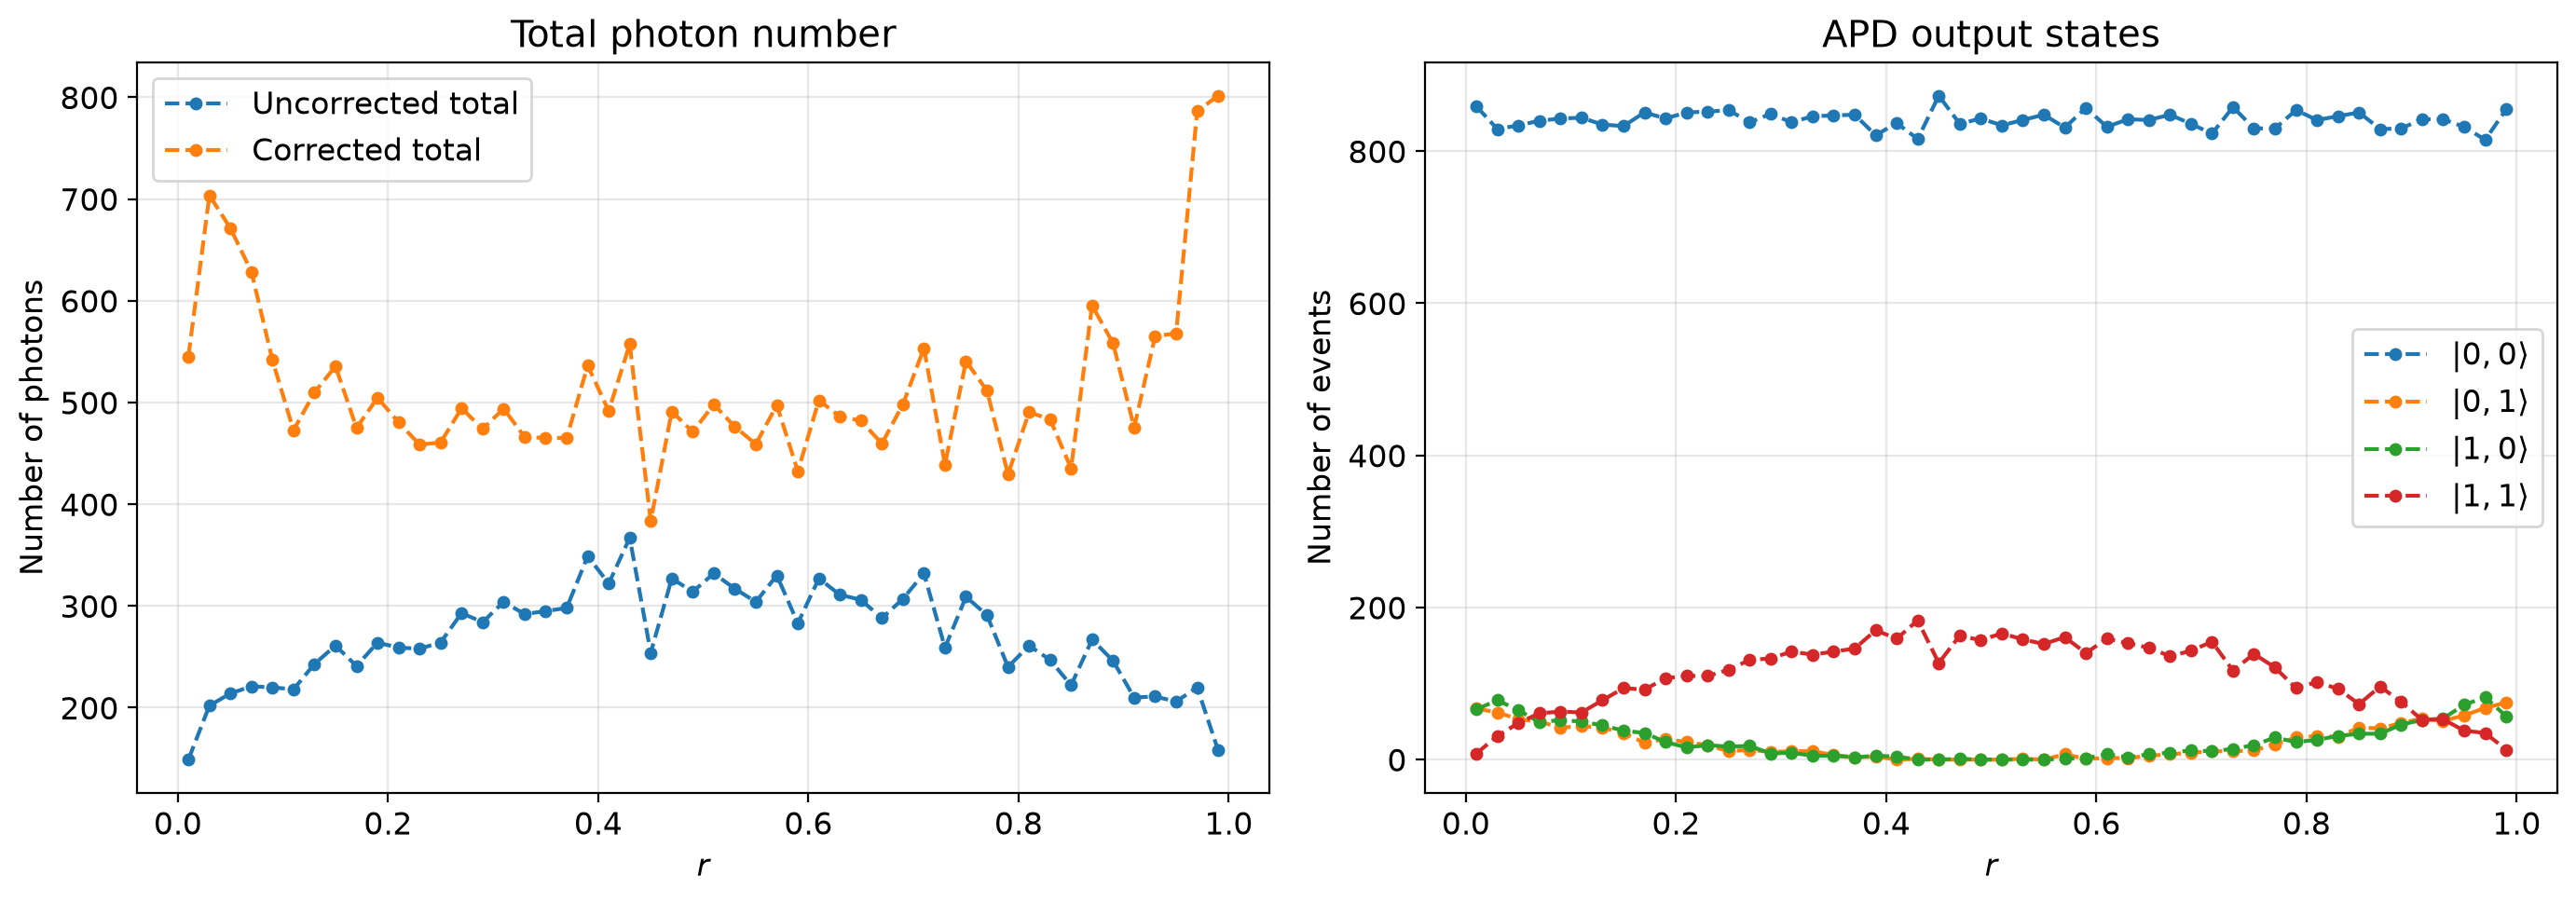

In [82]:
lam = 0.4
state = tmsv(lam, N_MAX = 4)
result = []

n_samples = 1000

# Reflectivity range
rs = np.linspace(0.01, 0.99, 50)

# Total number of detected photons/clicks
total_photons_apd = []

# Corrected number of photons
corrected_photons = []

for r in rs:

    proc = pcvl.Processor(
        "SLOS",
        coincidence_mod(r),
        noise=pcvl.NoiseModel(brightness=1.)
    )

    proc.with_input(state)


    detector1 = pcvl.Detector.threshold() # PNR
    detector1.efficiency = eta1 # efficiency
    proc.add(0, detector1)

    detector2= pcvl.Detector.threshold() # PNR
    detector2.efficiency = eta2 # efficiency
    proc.add(1, detector2)

    proc.min_detected_photons_filter(0)

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    # APD can only give 0 or 1 in each mode
    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

    result.append(counts)

    # Number of detected photons/clicks
    N_photons = (
        counts['01']
        + counts['10']
        + 2 * counts['11']
    )

    # Coincidences
    C = counts['11']
    t = 1 - r

    # Correction
    M = ((t) / (2* r) + (r) / (2* t)) * C

    total_photons_apd.append(N_photons + M)
    corrected_photons.append(M)


# Convert to numpy arrays
total_photons_apd = np.array(total_photons_apd)
corrected_photons = np.array(corrected_photons)


# =========================================================
# Additional quantities for plotting
# =========================================================

# Uncorrected total number of photons
uncorrected_photons = np.array([
    counts['01'] + counts['10'] + 2 * counts['11']
    for counts in result
])

# Individual states
n00 = np.array([counts['00'] for counts in result])
n01 = np.array([counts['01'] for counts in result])
n10 = np.array([counts['10'] for counts in result])
n11 = np.array([counts['11'] for counts in result])


# =========================================================
# Plots
# =========================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Uncorrected and corrected total photons
# ---------------------------------------------------------

ax1.plot(
    rs,
    uncorrected_photons,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Uncorrected total'
)

ax1.plot(
    rs,
    total_photons_apd,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Corrected total'
)

# True number of photons entering the circuit
#ax1.axhline(
#    2 * n_samples*eta1,
#    color='black',
#    linestyle='--',
#    linewidth=1.5,
#    label='Input photon number'
#)

ax1.set_xlabel(r'$r$')
ax1.set_ylabel('Number of photons')
ax1.set_title('Total photon number')

ax1.grid(True, alpha=0.3)
ax1.legend()


# ---------------------------------------------------------
# Plot 2: APD output states
# ---------------------------------------------------------

ax2.plot(
    rs,
    n00,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,0\rangle$'
)

ax2.plot(
    rs,
    n01,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,1\rangle$'
)

ax2.plot(
    rs,
    n10,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,0\rangle$'
)

ax2.plot(
    rs,
    n11,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,1\rangle$'
)

ax2.set_xlabel(r'$r$')
ax2.set_ylabel('Number of events')
ax2.set_title('APD output states')

ax2.grid(True, alpha=0.3)
ax2.legend()


plt.tight_layout()
plt.show()

In [ ]:
### 1000_termico = (1/2)*(N_spdc + M)

Here we have a clear problem: our correction overestimates the number of photons. I am not even sure if I can use this correction in this case. It seems to me that I could, because it can be generally derived from the comparison of PNRs and APDs. But maybe for higher number of photons this doensnt really work ?

### AI use:
Chat gpt was used to correct the codes.

In [18]:
N_MAX = 4
def thermal_x_vacuum(lam: float, n_max: int = N_MAX):
    """
    Two-mode mixed state:
        rho = rho_thermal ⊗ |0><0|

    Mode 0: thermal state obtained from one arm of TMSV
    Mode 1: vacuum
    """
    lam = float(lam)

    weights = [lam**(2*n) for n in range(n_max + 1)]
    Z = sum(weights)

    svd = pcvl.SVDistribution()

    for n, w in enumerate(weights): # n, w in (1, w_1) ex.
        p_n = w / Z

        # |n, 0>
        state = pcvl.StateVector(
            pcvl.BasicState([n, 0])
        )

        svd[state] = p_n # associated probability to our state

    return svd
